# Practical 5: working with public single-cell data from the fly brain

**ISN Neurochemistry School 2026**

Think of a gene, a cell type or a brain region you work on. By the end of this
hour you can find out which cells of the fly brain transcribe that gene, what
else those cells transcribe, and whether the DNA around it is open in them.
All of it is public data, published by other laboratories and free for you to
use in your own research.

The worked example is one pair of cell types:

> Can a Kenyon cell be distinguished from a glial cell using published
> single-cell data, and do expression and accessibility give the same answer?

Sections 3, 5 and 7 then hand the same three tools to a cell type, a gene and
a region of your own choosing.

**If you have not worked on flies before.** Kenyon cells are the neurons of
the mushroom body, which is the fly's centre for learning and memory, and
there are about 2,000 of them per hemisphere. The four cell types used
throughout are two kinds of Kenyon cell, gamma and alpha/beta, which differ
in where their axons go; `T1`, a neuron of the optic lobe, the visual part of
the brain; and astrocyte-like glia, which contact synapses and take up
neurotransmitter much as mammalian astrocytes do.

**Two reasons this is worth your time beyond today.**

- **It joins molecules to anatomy.** A connectome names cell types by their
  shape and connections. An atlas names the same cell types by what they
  transcribe. The cell type name is what joins the two, so a structure you
  know anatomically can be looked up molecularly.
- **It tests a claim instead of citing one.** "This marker is specific to my
  cell type" is a statement about 30,789 cells. Section 2 checks one in a
  minute, and the answer is not always the one in the textbook.

No raw sequencing data is processed here. You download the authors' processed
results and analyse them with the standard tools: `scanpy` for expression,
`pandas` for tables, `pyBigWig` for coverage.

**Outline**

1. The datasets
2. Gene expression in the adult brain (Fly Cell Atlas)
3. Differential expression to find marker genes
4. The larval brain, which still contains neural progenitors *(optional)*
5. Chromatin accessibility (Janssens et al. 2022)
6. Finding cell-type-specific regions *(optional)*
7. Candidate enhancers for Practical 6

Everything runs on a laptop CPU. The two optional sections can be skipped
without breaking anything later.

## Running on Google Colab

Run this cell first.

In [1]:
# Colab setup. On a laptop install this cell does nothing.
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import os

    !pip install -q pyBigWig scanpy "pandas==2.2.3"

    # Get the course files, or update them if this session already has them.
    # Re-running this cell, or opening both practicals in one session, is fine.
    import subprocess

    if os.path.isdir("/content/course/.git"):
        # An update is refused if anything in that folder has been edited.
        # Stopping here would be unhelpful and discarding the edit silently
        # would be worse, so report it and carry on with what is already there.
        update = subprocess.run(
            ["git", "-C", "/content/course", "pull", "--quiet", "--ff-only"],
            capture_output=True, text=True,
        )
        if update.returncode:
            print("Could not update the course files. Continuing with the copy")
            print("already in this session, which is almost certainly fine.")
    else:
        !rm -rf /content/course
        !git clone -q https://github.com/nkempynck/isn-school-2026 /content/course
    %cd /content/course
    print("Ready.")
else:
    print("Running locally, nothing to install.")

Running locally, nothing to install.


## 0. Setup

Imports and paths. If this fails, sort it out before going further.

In [2]:
import importlib.metadata
import sys
from pathlib import Path

# Locate the course folder, independent of where Jupyter was started
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.set_figure_params(figsize=(6, 5), dpi=90, frameon=False)

print("scanpy", importlib.metadata.version("scanpy"))
print("course folder:", ROOT)

scanpy 1.12.4
course folder: /Users/u0132293/Documents/software/coursework


## 1. The datasets

| | Gene expression | Chromatin accessibility |
|---|---|---|
| Publication | Li, Janssens et al. 2022, *Science* 375:eabk2432 | Janssens et al. 2022, *Nature* 601:630 |
| Dataset | Fly Cell Atlas, 10x head | adult brain scATAC-seq |
| Source | <https://flycellatlas.org> | <https://flybrain.aertslab.org>, GEO GSE163697 |

The Fly Cell Atlas is the reference single-cell atlas for *Drosophila*. We use
the head and keep only its brain cell types. A third dataset, the larval brain
of Ravenscroft et al. 2019, appears in section 4.

The published head file is 2.5 GB, more than an 8 GB laptop can subset.
`scripts/prepare_data.py` reduces it once to a 44 MB file. Nothing is
recomputed: the counts, embeddings and annotations are the authors'.

### Where every file comes from

Nothing in this course is our data. Each file below is downloaded from the group
that published it, and `scripts/download_data.py` prints the URL as it fetches,
so you can always trace a number back to its source.

| file | from | link |
|---|---|---|
| Fly Cell Atlas head, 10x stringent | Li, Janssens et al. 2022 | <https://flycellatlas.org> |
| adult brain ATAC tracks and peaks | Janssens et al. 2022 | <https://flybrain.aertslab.org/downloads/>, GEO GSE163697 |
| the 54 enhancers tested in flies | Janssens et al. 2022, Figure 4 | `downloads/other/enhancersTested.bed` at the same portal |
| larval brain, 3rd instar | Ravenscroft et al. 2019 | <https://flybrain.aertslab.org/downloads/loom/> |
| dm6 genome | UCSC | <https://hgdownload.soe.ucsc.edu/goldenPath/dm6/bigZips/> |

If you want to work with any of these after the school, start from those links
rather than from this repository. Please cite the groups that published the
data, not the course.

In [3]:
from scripts.prepare_data import make_fca_brain_h5ad, make_larval_h5ad

# These give us the two small files the practical uses. If they are already on
# this machine, or on the course mirror, nothing is recomputed. Only if both
# are unavailable does it fall back to downloading the authors' original files,
# which for the Fly Cell Atlas means 2.5 GB.
make_fca_brain_h5ad()   # -> data/processed/fca_brain.h5ad    (44 MB)
make_larval_h5ad()      # -> data/processed/larval_brain.h5ad (22 MB)
None                    # the paths are not needed here

  already prepared: fca_brain.h5ad (44 MB)
  already prepared: larval_brain.h5ad


## 2. Gene expression

From here on this is ordinary `scanpy`. The same commands work on any h5ad file
you download in future, so they are worth reading rather than just running.

In [4]:
adata = sc.read_h5ad(ROOT / "data" / "processed" / "fca_brain.h5ad")
adata

AnnData object with n_obs × n_vars = 30789 × 13056
    obs: 'annotation', 'annotation_broad', 'annotation_broad_extrapolated', 'sex', 'n_genes'
    var: 'is_TF'
    uns: 'source'
    obsm: 'X_tsne', 'X_umap'
    layers: None (.X)

That summary is the structure of an `AnnData` object, which is how `scanpy`
holds a dataset:

- `n_obs x n_vars` is cells by genes
- `obs` holds per-cell information, including the cell type annotation
- `var` holds per-gene information, here a flag for transcription factors
- `obsm` holds per-cell coordinates, here the authors' t-SNE and UMAP

The expression values themselves are in `X`. The authors have already
processed them so that one cell can be compared with another, so the file is
used exactly as it was downloaded.

In [5]:
adata.obs["annotation"].value_counts().head(10)

annotation
ensheathing glial cell                         1855
adult brain perineurial glial cell             1640
columnar neuron T1                             1618
T neuron T4/T5a-b                              1525
lamina monopolar neuron L2                     1238
gamma Kenyon cell                              1139
lamina monopolar neuron L3                     1047
medullary intrinsic neuron Mi1                 1001
adult lamina epithelial/marginal glial cell     984
transmedullary neuron Tm1                       957
Name: count, dtype: int64

### Two levels of annotation

Both are columns in `obs`: `annotation_broad`, the coarse class, which here has
two values, neuron and glial cell; and `annotation`, the cell type, with 62
values. Start with the coarse one.

These 30,789 cells are the ones the atlas gave a brain cell type to. The
published head file holds 100,527, and 44,956 of those were never annotated at
all. Most of them are brain: the atlas's own extrapolated labels call 38,219 of
them neurons or glia. We keep the named ones, because every question in this
notebook starts from a cell type, but a published atlas is usually a named
minority rather than a finished map. Davie et al. 2018 left 54% of their adult
brain cells unnamed.

**How to read the plot below.** It is a t-SNE. Every point is one cell, and
cells whose overall gene expression is similar are placed near each other. It
takes the 13,056 numbers measured in each cell and reduces them to two
coordinates, so the axes carry no units and the distance between two groups
far apart means little. What it is good for is seeing which cells group
together, and whether those groups correspond to the labels.

The file carries two such sets of coordinates, a t-SNE and a UMAP. This
notebook uses the t-SNE, which separates these cell types more cleanly and is
what the SCope portal shows. `sc.pl.tsne` draws the coordinates stored in
`obsm["X_tsne"]`.

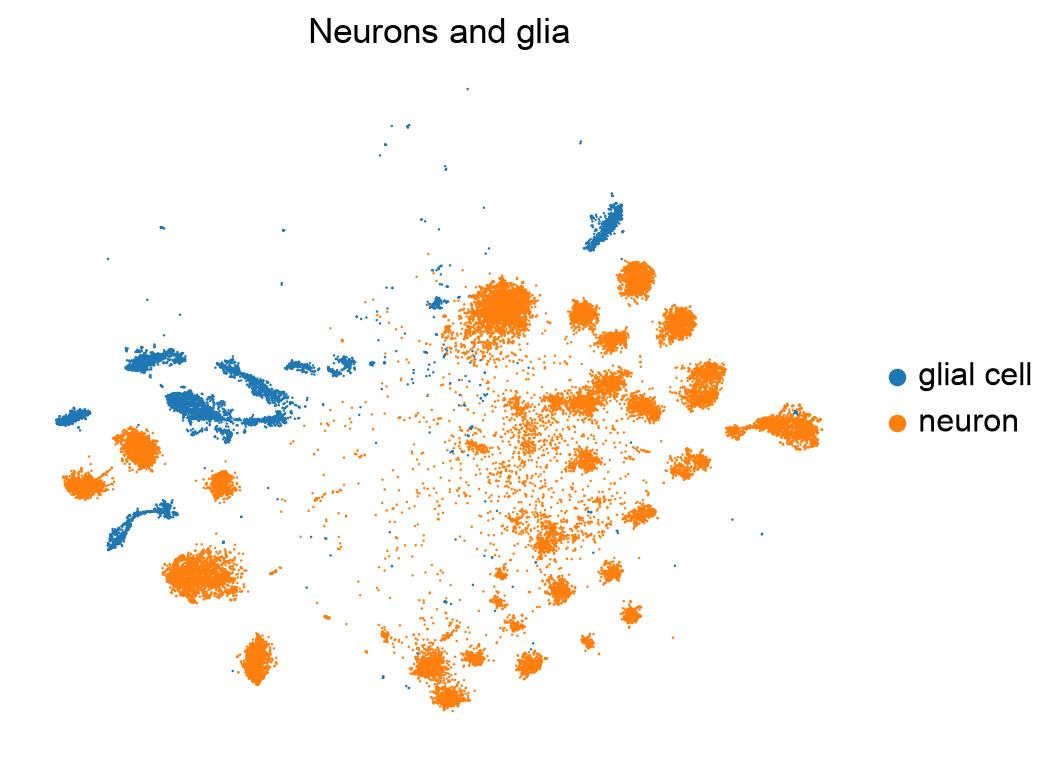

In [6]:
sc.pl.tsne(adata, color="annotation_broad", title="Neurons and glia", frameon=False)

The glial cells form a few groups away from the main mass of neurons. That is
the split section 5 looks for in the chromatin.

Now the same map at cell type resolution. The figure is large; zoom in to read
it.

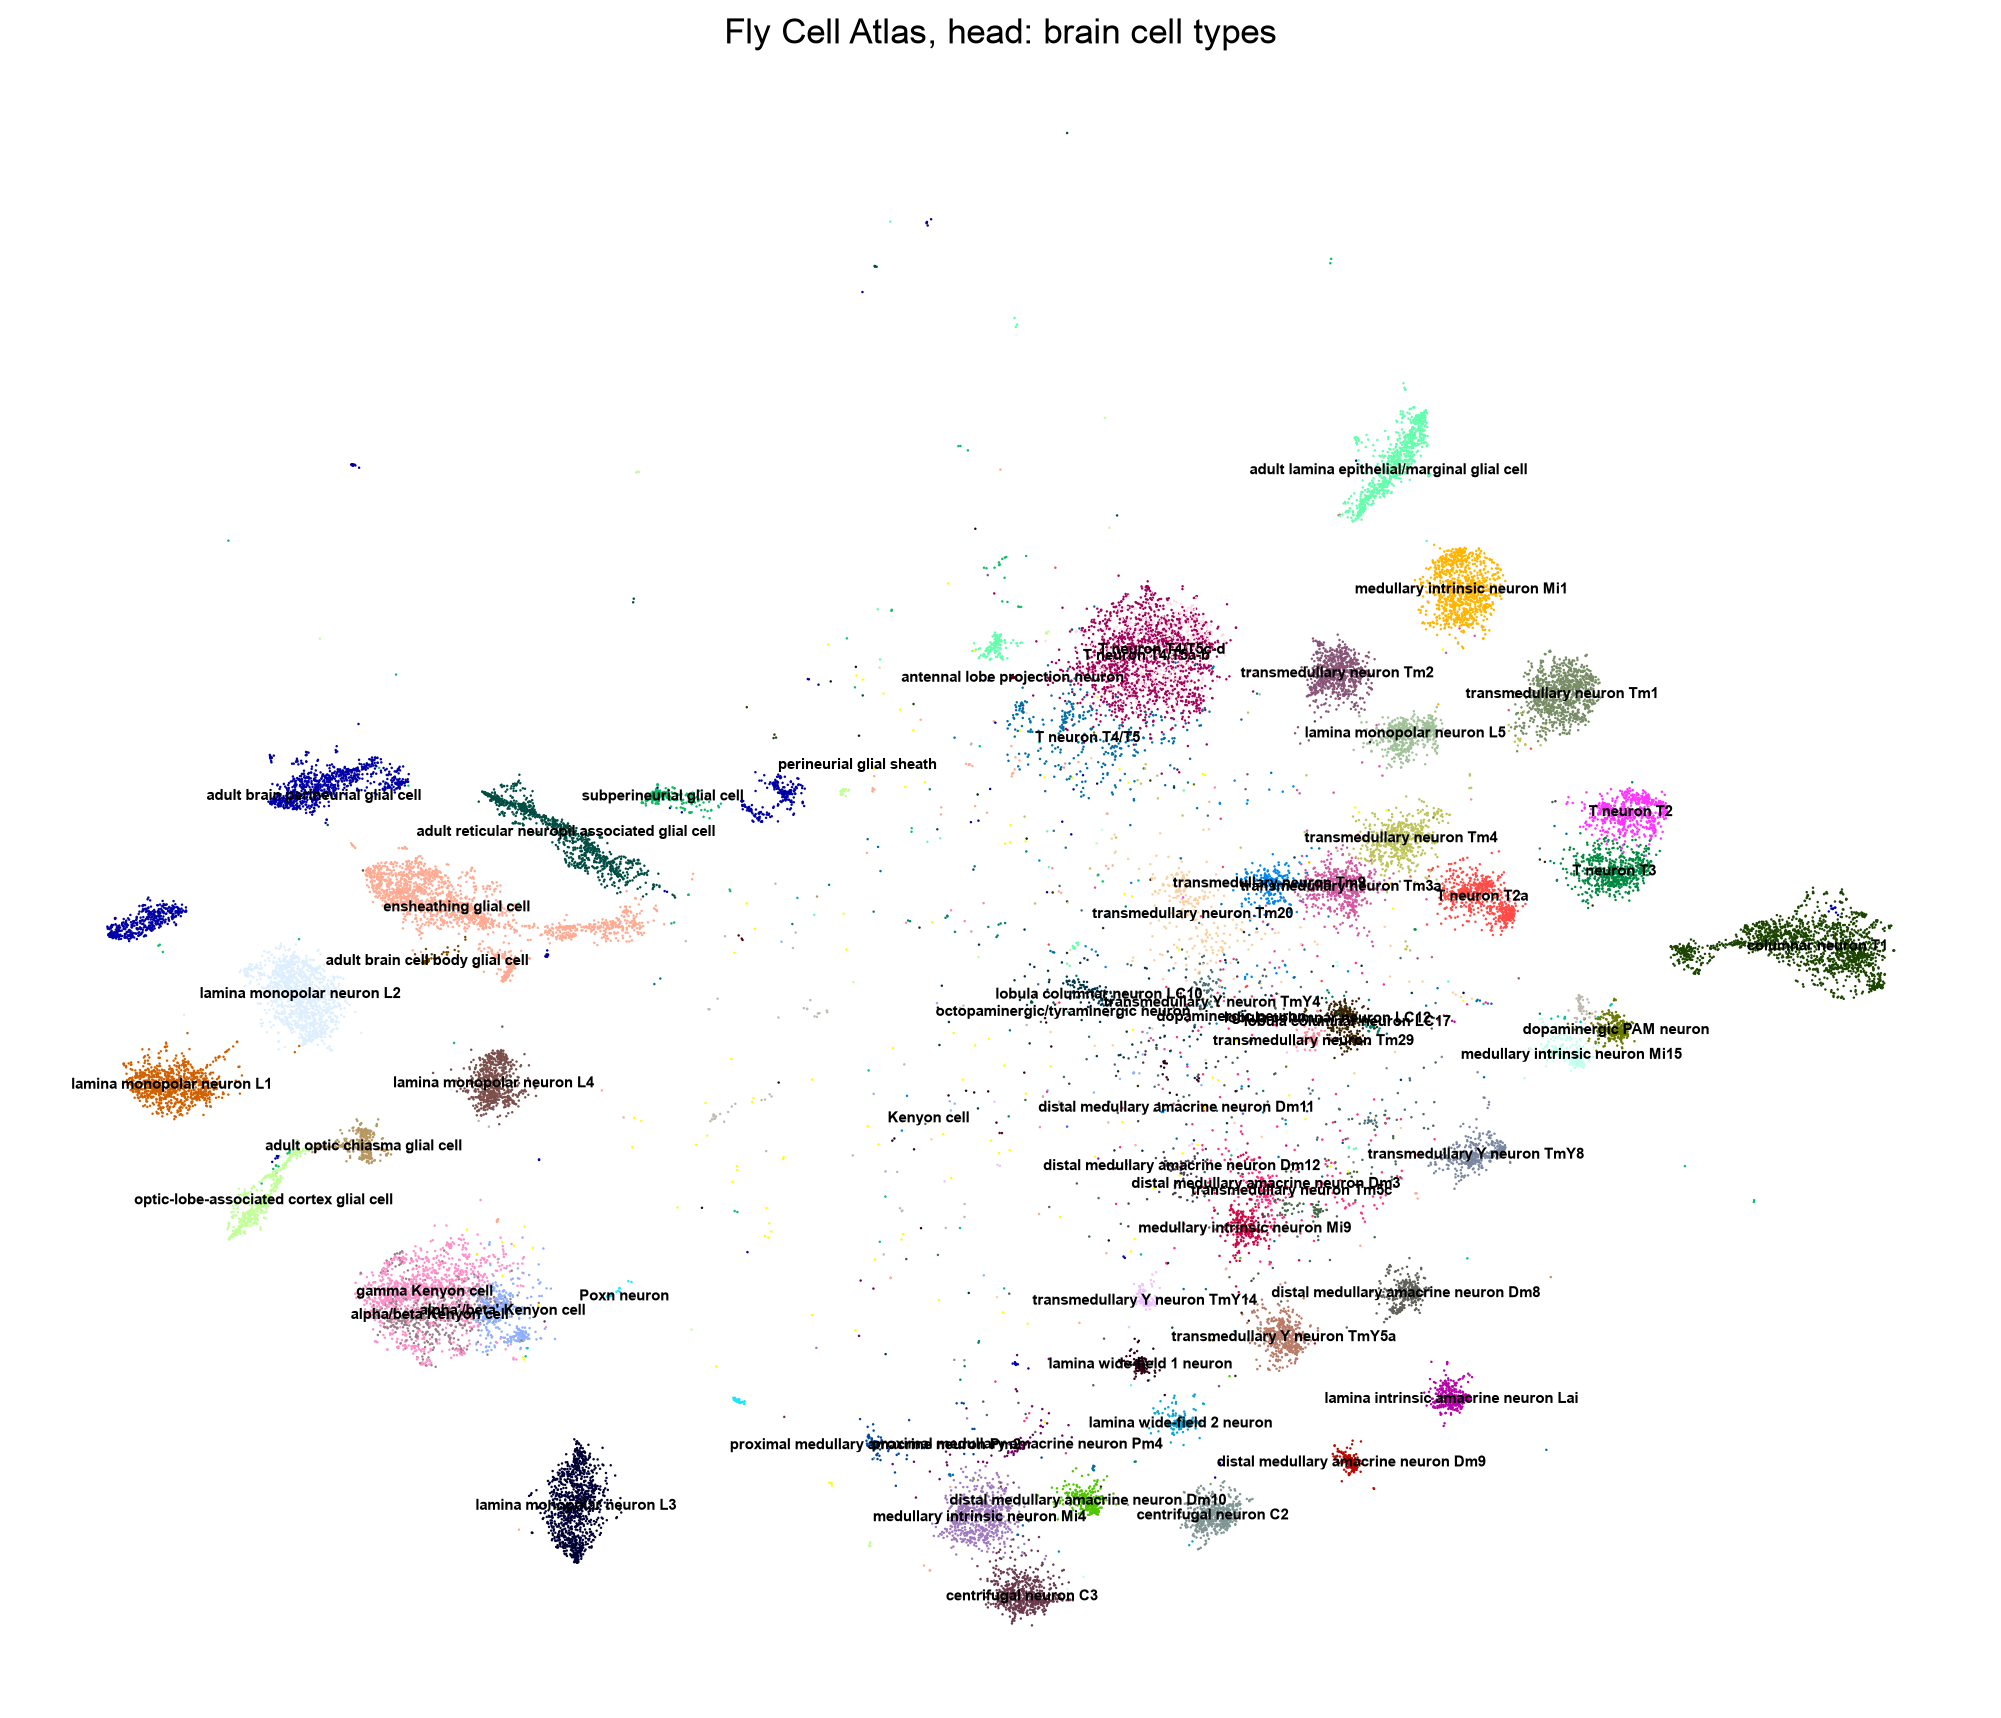

In [7]:
# 62 cell type labels need a bigger canvas than the default. `plt.rc_context`
# changes the figure size for this plot only.
with plt.rc_context({"figure.figsize": (14, 12)}):
    sc.pl.tsne(
        adata,
        color="annotation",
        legend_loc="on data",
        legend_fontsize=6,
        title="Fly Cell Atlas, head: brain cell types",
        frameon=False,
    )

Points to note:

- Optic lobe neurons dominate, 44 of the 62 types and about 69% of the cells:
  the T, Tm, Mi, Dm and L families. The optic lobes hold most of the neurons in
  the fly brain, so this is expected
- The two largest single types are nonetheless glial, not neuronal
- Glial types form their own groups, separate from all neurons
- The Kenyon cell types sit together

### The four cell types used in this practical

These are the types for which we also have ATAC data. The two datasets name them
differently, so `scripts/celltypes.py` holds the mapping.

In [8]:
from scripts.celltypes import ATAC_TO_RNA

CELL_TYPES = ["KC_g", "KC_ab", "T1", "Astrocyte_like"]
our_types = [ATAC_TO_RNA[ct] for ct in CELL_TYPES]

for atac, rna in ATAC_TO_RNA.items():
    print(f"{atac:20s} -> {rna}")

KC_g                 -> gamma Kenyon cell
KC_ab                -> alpha/beta Kenyon cell
KC_abPrime           -> alpha'/beta' Kenyon cell
T1                   -> columnar neuron T1
T2                   -> T neuron T2
T2a                  -> T neuron T2a
T3                   -> T neuron T3
Astrocyte_like       -> adult reticular neuropil associated glial cell
Ensheathing_glia     -> ensheathing glial cell
Cortex_glia          -> optic-lobe-associated cortex glial cell
Perineurial_glia     -> adult brain perineurial glial cell
Subperineurial_glia  -> subperineurial glial cell
Chiasm_glia          -> adult optic chiasma glial cell


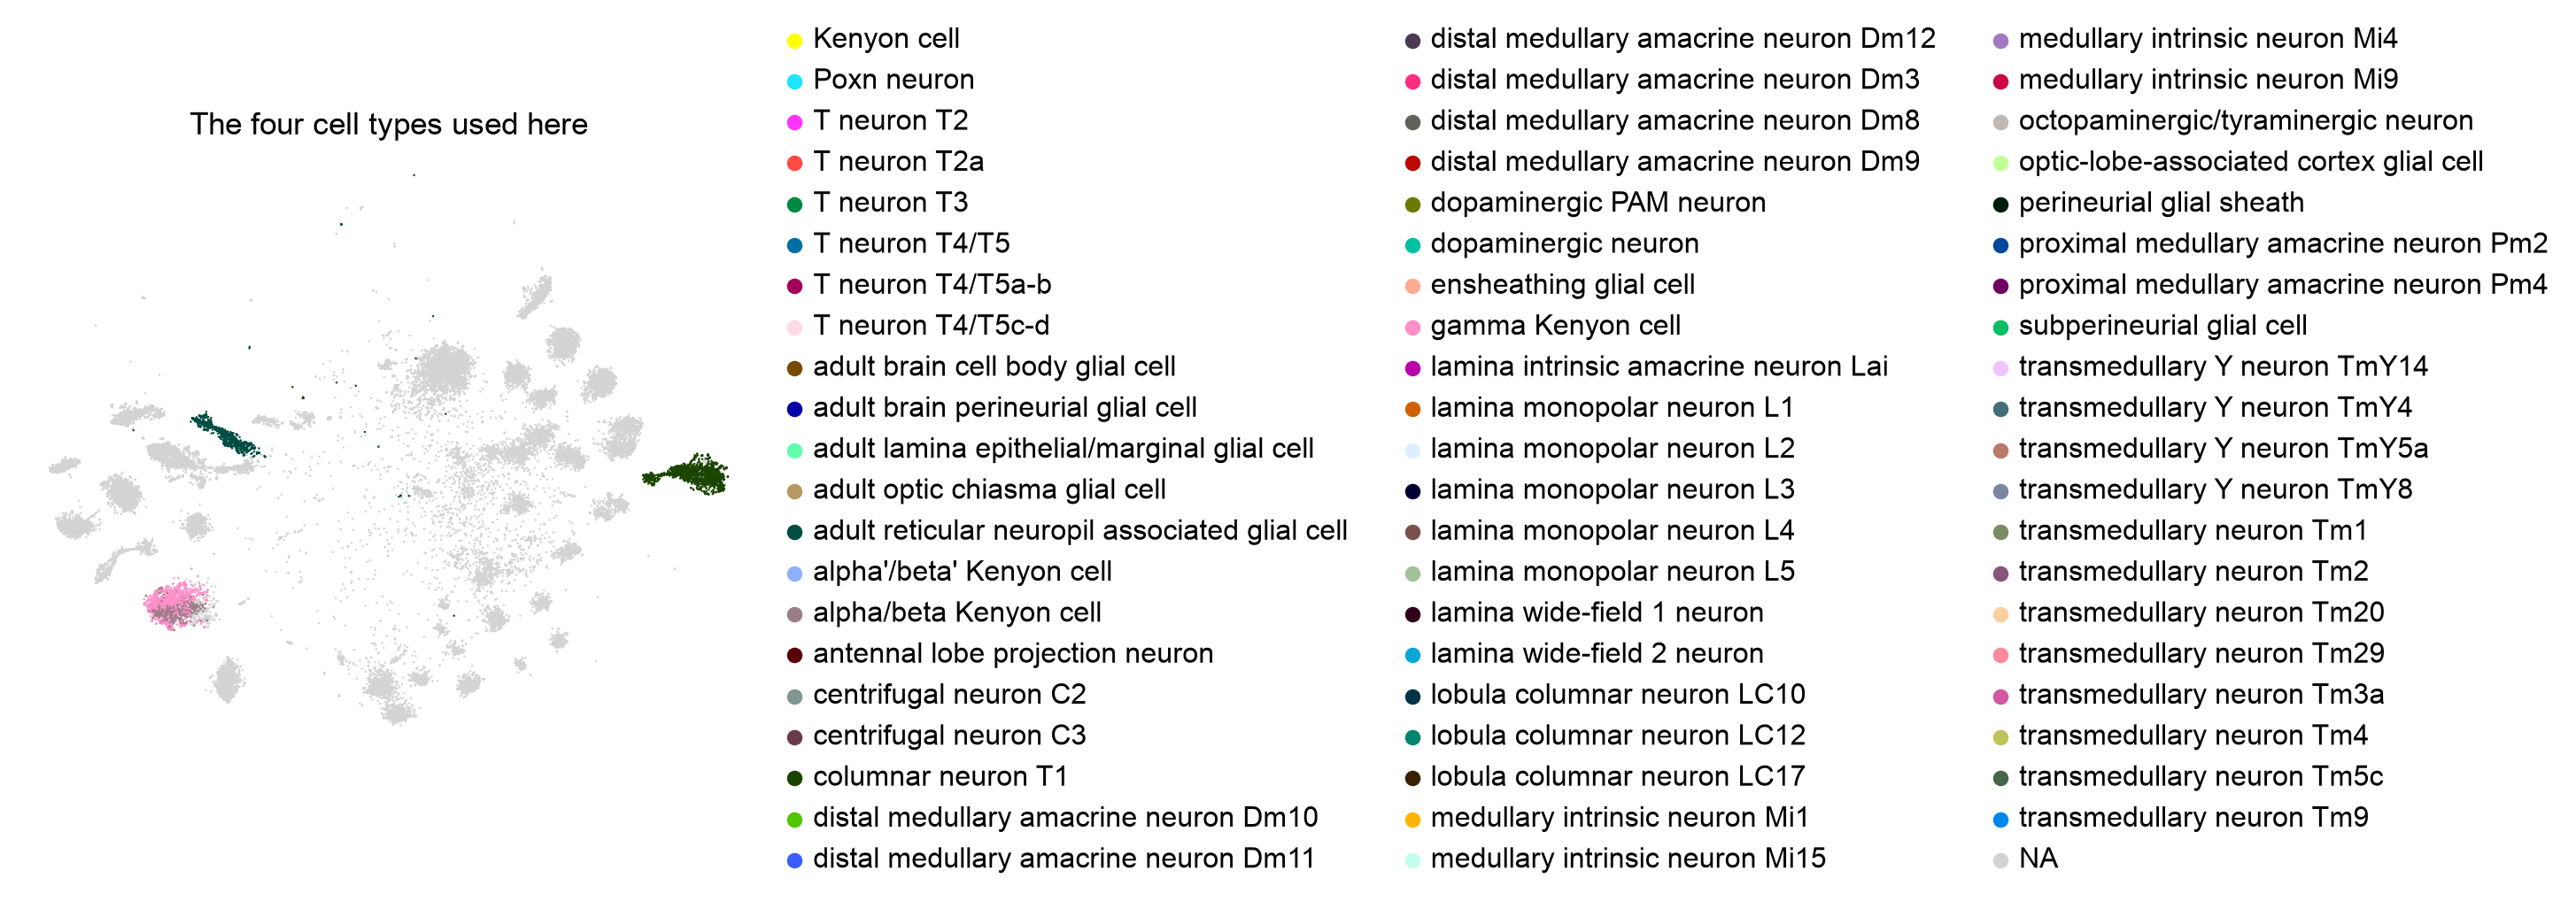

In [9]:
# A column that is the cell type name for our four types and NaN elsewhere,
# which makes scanpy grey out everything else.
adata.obs["focus"] = adata.obs["annotation"].where(
    adata.obs["annotation"].isin(our_types)
)

sc.pl.tsne(adata, color="focus", title="The four cell types used here", frameon=False)

### Expression of a marker gene

`repo` encodes a transcription factor required for glial differentiation, and is
expressed in glia but not in neurons, so it should pick out the glial groups
and nothing else.

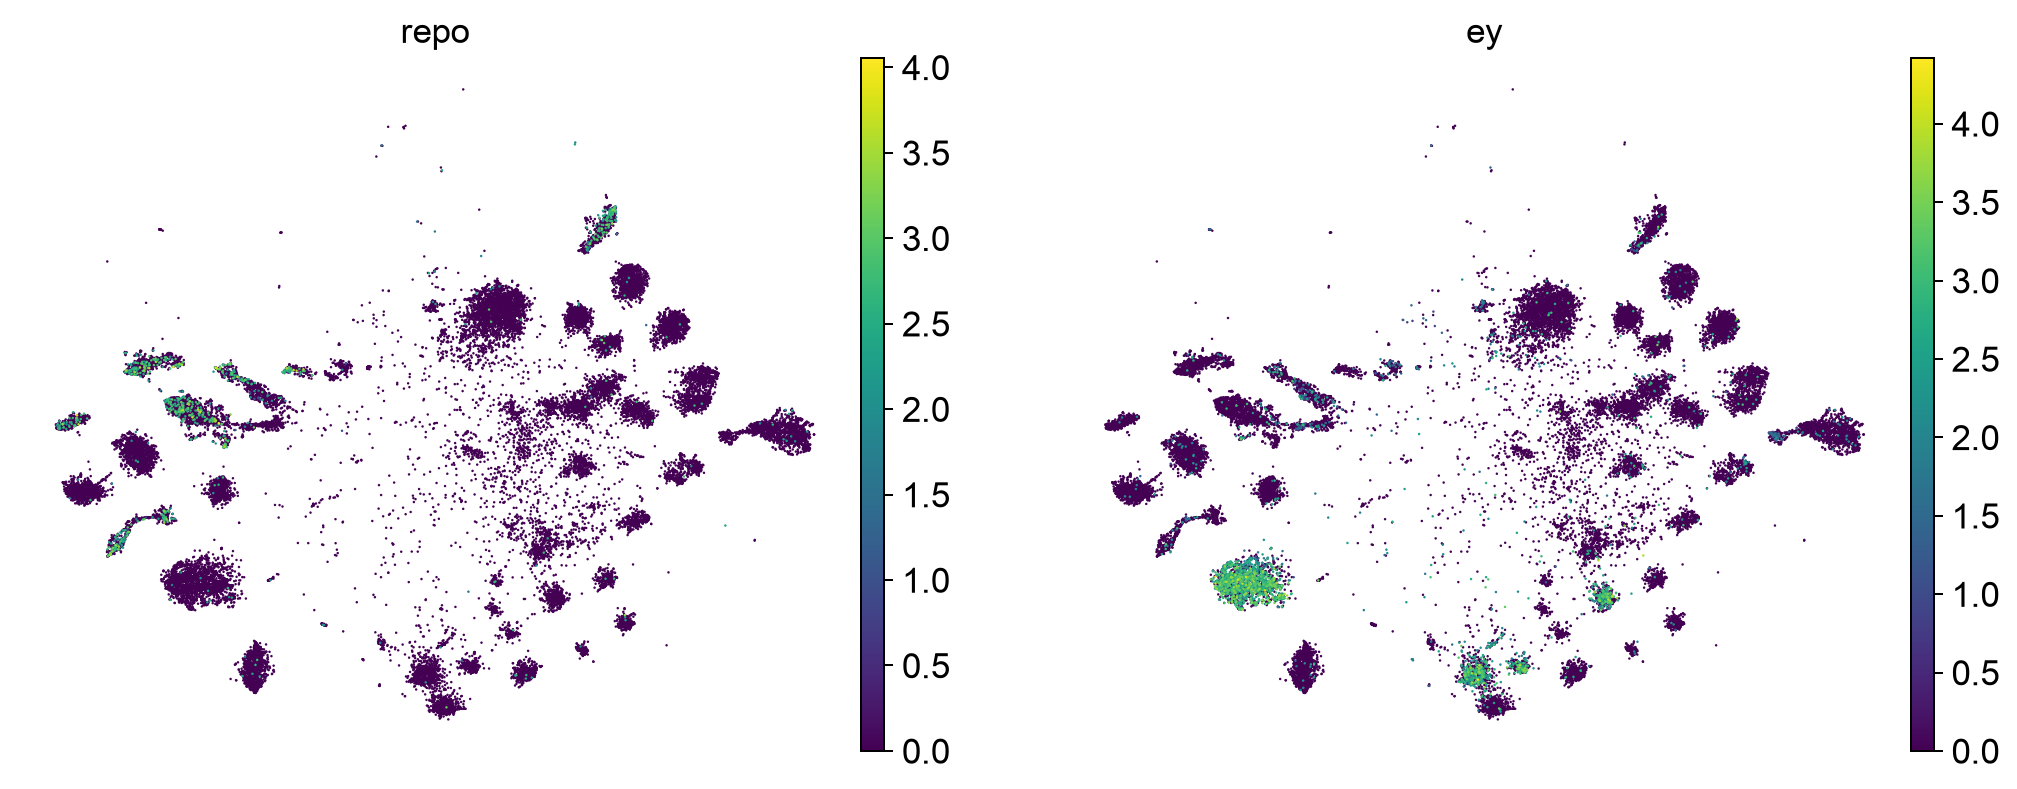

In [10]:
sc.pl.tsne(adata, color=["repo", "ey"], frameon=False, ncols=2)

`repo` is restricted to the glial groups. `ey` (*eyeless*, a Pax6 homologue) is
concentrated in the Kenyon cells.

### The numbers behind the picture

A projection is not a measurement. `sc.get.obs_df` pulls expression values into a
pandas table, which can then be grouped by cell type.

In [11]:
values = sc.get.obs_df(adata, keys=["repo", "ey", "alrm", "annotation"])
means = values.groupby("annotation", observed=True).mean()

means.sort_values("repo", ascending=False).head(6).round(2)

,repo,ey,alrm
annotation,,,
subperineurial glial cell,0.40,0.04,0.02
optic-lobe-associated cortex glial cell,0.39,0.10,0.01
adult lamina epithelial/marginal glial cell,0.31,0.08,0.02
adult optic chiasma glial cell,0.31,0.02,0.03
ensheathing glial cell,0.28,0.07,0.04
adult brain perineurial glial cell,0.28,0.05,0.01


The highest cell types for `repo` are all glial. `alrm`, an astrocyte marker,
should be far more restricted; compare the two columns.

The numbers are mean expression per cell type, averaged over
every cell of that type including the ones where the gene was not detected at
all. `repo` is detected in only 11 to 16% of cells even in glia, so 0.40 is an
average over mostly zeros rather than a typical cell's level. In the cells that
do carry it the value is around 2.6, which is the range the colour bar on the
plot above shows. Use these numbers to rank cell types rather than as an amount
of anything, and note that the dot plot below separates the two things a mean
runs together: how high, and in how many cells.

In [12]:
means.sort_values("alrm", ascending=False).head(6).round(2)

,repo,ey,alrm
annotation,,,
adult reticular neuropil associated glial cell,0.22,0.15,0.95
lobula columnar neuron LC12,0.00,0.17,0.05
lamina intrinsic amacrine neuron Lai,0.02,0.02,0.04
ensheathing glial cell,0.28,0.07,0.04
medullary intrinsic neuron Mi15,0.01,0.05,0.04
medullary intrinsic neuron Mi9,0.02,0.12,0.04


### A dot plot across the four cell types

`sc.pl.dotplot` is the usual way to show several genes across several cell types
at once. Colour is mean expression, dot size is the fraction of cells in which
the gene was detected.

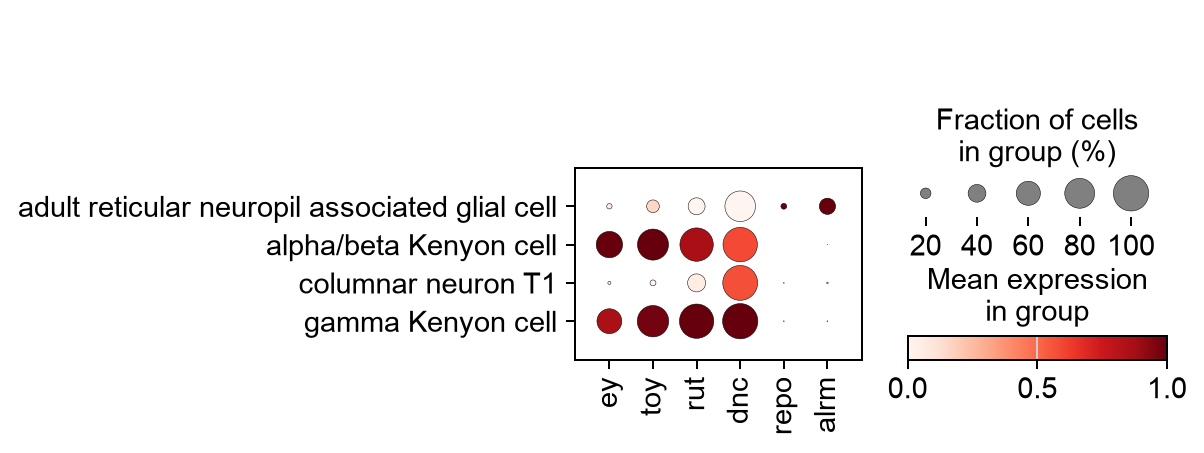

In [13]:
sc.pl.dotplot(
    adata[adata.obs["annotation"].isin(our_types)],
    var_names=["ey", "toy", "rut", "dnc", "repo", "alrm"],
    groupby="annotation",
    standard_scale="var",
)

## 3. Finding marker genes rather than assuming them

So far we started from genes already known to mark a cell type. When you do not
know them, the standard approach is a differential expression test: for each
gene, compare one cell type against all others.

`sc.tl.rank_genes_groups` does this. The Wilcoxon test is the usual choice for
single-cell data because it assumes nothing about the shape of the
distribution. It takes about 15 seconds here.

In [14]:
sc.tl.rank_genes_groups(
    adata,
    groupby="annotation",
    groups=["gamma Kenyon cell"],
    reference="rest",
    method="wilcoxon",
)

markers = sc.get.rank_genes_groups_df(adata, group="gamma Kenyon cell")
markers.head(12).round(3)

,names,scores,logfoldchanges,pvals,pvals_adj
0,rad,51.997002,5.669,0.0,0.0
1,mub,51.297001,3.298,0.0,0.0
2,Rgk1,51.129002,5.143,0.0,0.0
3,rut,49.076000,4.340,0.0,0.0
4,Pka-R2,46.139000,3.877,0.0,0.0
5,Dop1R2,44.771000,5.552,0.0,0.0
6,Pka-C1,44.316002,3.324,0.0,0.0
7,sNPF,44.007000,5.083,0.0,0.0
8,dnc,42.896999,2.391,0.0,0.0
9,CG32204,42.437000,4.900,0.0,0.0


`scores` is the test statistic, `logfoldchanges` the effect size, and
`pvals_adj` the p-value after correction for multiple testing.

Several are recognisable. `rut` (*rutabaga*) and `dnc` (*dunce*) are the two
classical *Drosophila* learning mutants, and `Pka-C1`, `Pka-R2` and `Dop1R2`
belong to the same cAMP pathway. The mushroom body is the site of associative
learning in the fly, so recovering this pathway from an unsupervised test is a
useful check that the method is behaving.

`ey`, the marker used in section 2, is not among these twelve. It is rank 34 of
13,056 with an adjusted p-value of 2e-226, so the test does find it. It sits
below genes like `Rgk1` because the Wilcoxon test rewards consistent
separation, and `Rgk1` is detected in 97% of gamma Kenyon cells against `ey`'s
62%: a third of the cells look negative for `ey`. Rank is not importance. `ey`
is the transcription factor that specifies this cell type and it still loses to
more abundant genes, which is the usual fate of transcription factors in a list
like this and the reason for the next cell.

### Which of them are transcription factors?

Transcription factors bind DNA and could explain why a region is accessible,
which is what Practical 6 asks. The atlas carries FlyBase's classification in
`var`.

In [15]:
tf_names = adata.var_names[adata.var["is_TF"]]
print(f"{len(tf_names)} of {adata.n_vars} genes are annotated transcription factors")

markers[markers["names"].isin(tf_names)].head(10).round(3)

595 of 13056 genes are annotated transcription factors


,names,scores,logfoldchanges,pvals,pvals_adj
11,toy,41.964001,4.477,0.0,0.0
13,pros,41.216000,4.241,0.0,0.0
16,fru,38.120998,2.979,0.0,0.0
24,mamo,34.993000,2.217,0.0,0.0
33,ey,32.304001,4.553,0.0,0.0
40,dac,28.108000,3.544,0.0,0.0
61,ab,23.249001,2.185,0.0,0.0
75,Mef2,20.778999,1.892,0.0,0.0
78,dati,20.231001,3.110,0.0,0.0
120,sr,16.205000,2.307,0.0,0.0


`ey` and `toy` (*twin of eyeless*) are paralogous Pax6 transcription factors,
and both appear alongside `dac`, `mamo`, `pros` and `fru`. These are candidate
regulators of the Kenyon cell state.

That is a testable prediction: if they drive Kenyon cell identity, their binding
motifs should be enriched in regions accessible specifically in Kenyon cells.
Practical 6 asks a sequence model whether that is so.

### Your turn

> **Optional.**

Everything from here to the end of the section is code you have already run,
with one name changed. Pick a cell type, find the transcription factors that
mark it, see where its cells sit in the t-SNE, and look at some of its genes.

The cell below lists all 62 names with how many cells each has. Choose one
with a few hundred cells or more: a type with very few cells gives an
unreliable comparison.

In [16]:
# The 62 cell types in this file, largest first. Copy one of these names.
print(adata.obs["annotation"].value_counts().to_string())

annotation
ensheathing glial cell                            1855
adult brain perineurial glial cell                1640
columnar neuron T1                                1618
T neuron T4/T5a-b                                 1525
lamina monopolar neuron L2                        1238
gamma Kenyon cell                                 1139
lamina monopolar neuron L3                        1047
medullary intrinsic neuron Mi1                    1001
adult lamina epithelial/marginal glial cell        984
transmedullary neuron Tm1                          957
adult reticular neuropil associated glial cell     954
lamina monopolar neuron L1                         906
transmedullary neuron Tm2                          731
T neuron T4/T5c-d                                  693
lamina monopolar neuron L4                         660
medullary intrinsic neuron Mi4                     641
T neuron T2a                                       622
T neuron T3                                        617

In [17]:
MY_CELL_TYPE = "adult reticular neuropil associated glial cell"   # change this

sc.tl.rank_genes_groups(
    adata, groupby="annotation", groups=[MY_CELL_TYPE],
    reference="rest", method="wilcoxon", key_added="my_markers",
)

# The same transcription factor filter as above, so the two lists compare
# directly. The index numbers are each gene's position in the unfiltered
# ranking, which is why they jump.
my_markers = sc.get.rank_genes_groups_df(adata, group=MY_CELL_TYPE, key="my_markers")
my_tfs = my_markers[my_markers["names"].isin(tf_names)]

my_tfs.head(10).round(3)

,names,scores,logfoldchanges,pvals,pvals_adj
15,zfh2,30.500000,3.167,0.0,0.0
16,hth,30.402000,2.773,0.0,0.0
26,pnt,25.177999,3.823,0.0,0.0
28,pdm3,25.003000,2.785,0.0,0.0
30,ct,24.113001,2.250,0.0,0.0
41,CG42741,20.777000,7.606,0.0,0.0
43,pros,20.472000,2.392,0.0,0.0
50,Glut4EF,18.305000,0.786,0.0,0.0
54,ab,17.573999,1.762,0.0,0.0
69,Pdp1,15.211000,1.102,0.0,0.0


The glial transcription factors are led by `zfh2`, `hth` and `pnt`. Only
`pros` and `ab` also appear in the Kenyon cell list, so the two cell types are
characterised by largely different ones.

`repo` does not appear, although section 2 showed it is glial. It is itself a
transcription factor, so the filter did not remove it: it is rank 633 of 13,056
in this comparison. The test compares one cell type against all others, and the
other glial types also express `repo`, so it does not distinguish this
astrocyte population from them. **What counts as
a marker depends entirely on the comparison being made.**

Now look at the same cell type the other two ways. First where its cells
are, using the idiom from section 2: name the cells of one type and leave
the rest as `NaN`, which is what greys them out.

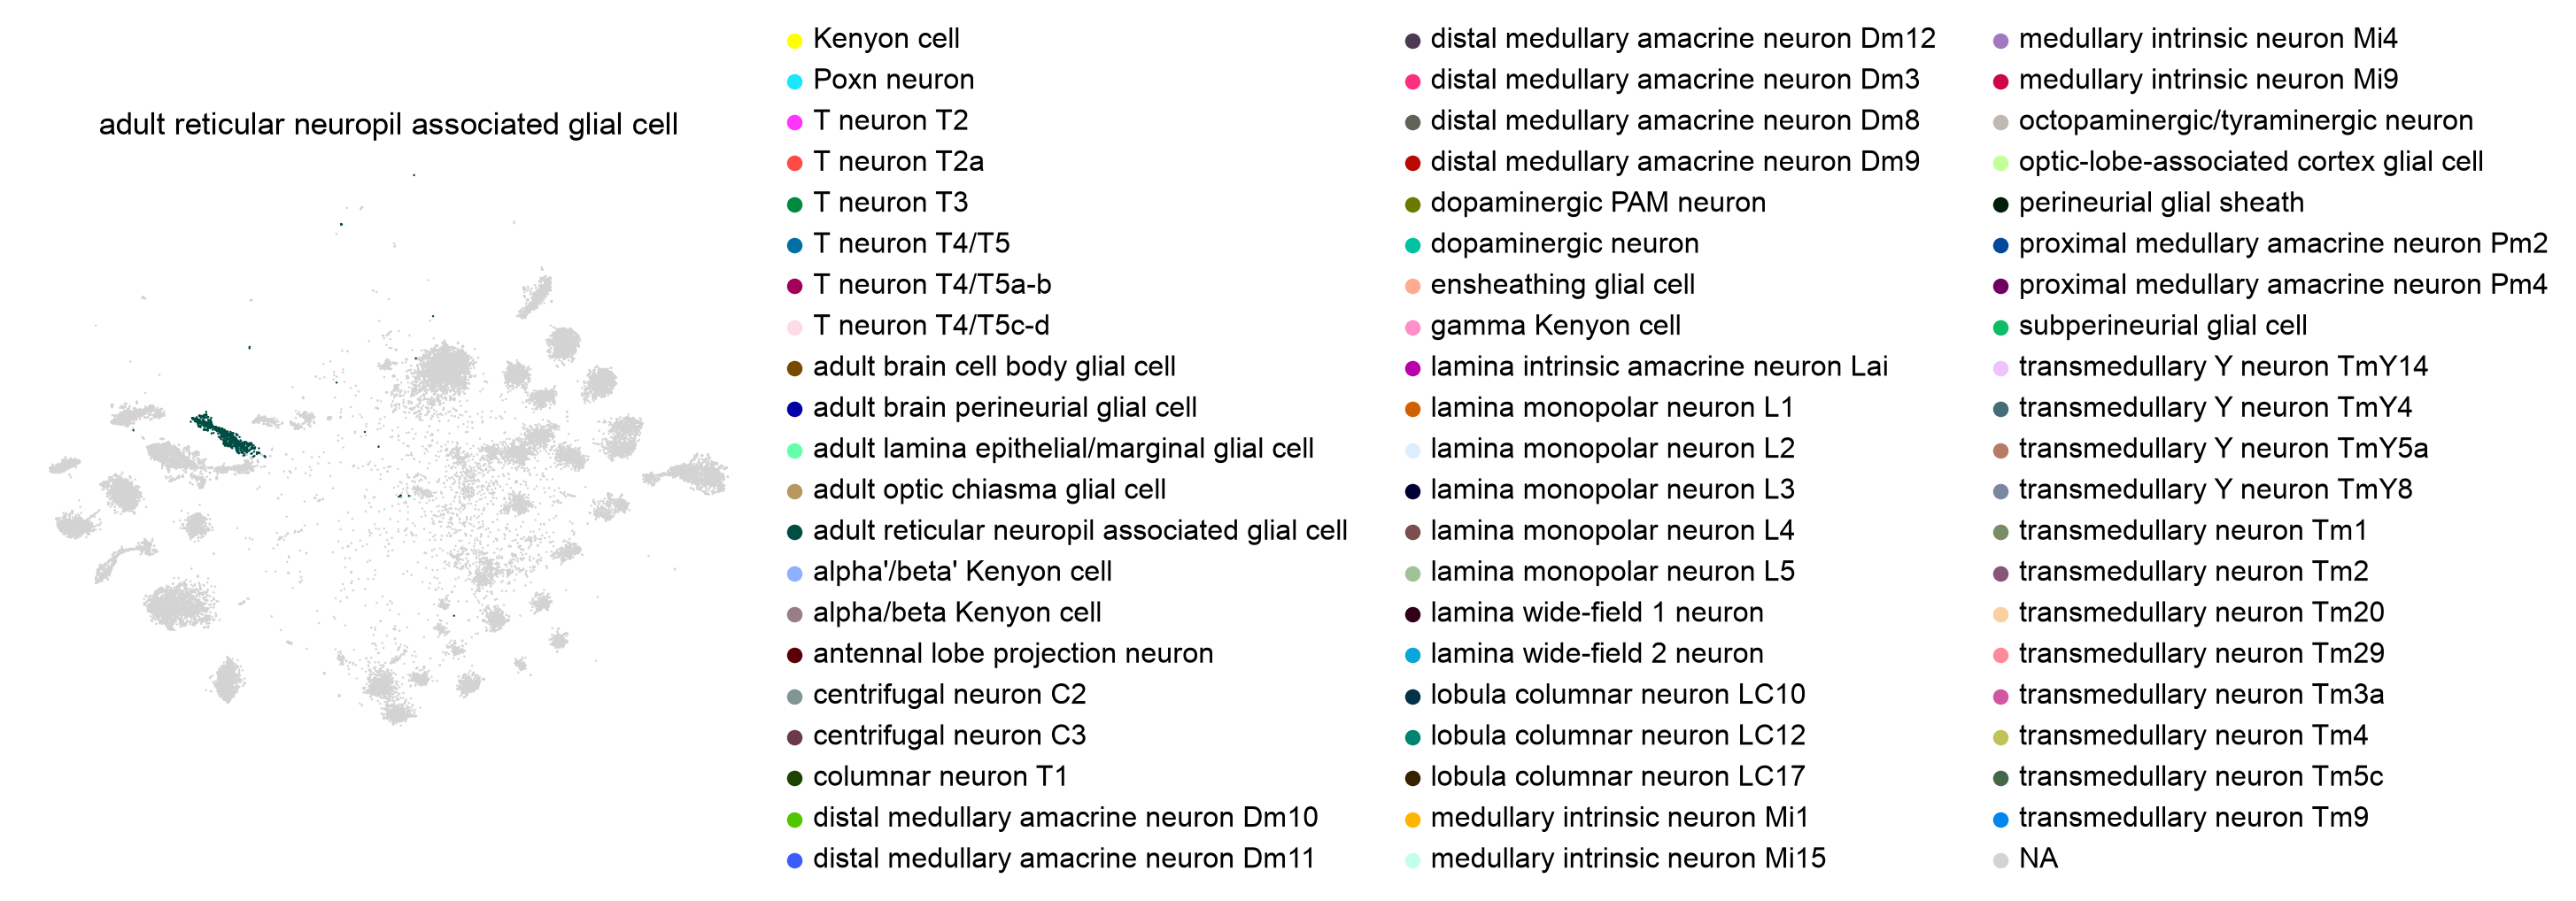

In [18]:
adata.obs["my_focus"] = adata.obs["annotation"].where(
    adata.obs["annotation"] == MY_CELL_TYPE
)

sc.pl.tsne(adata, color="my_focus", title=MY_CELL_TYPE, frameon=False)

Then the genes. This starts from the top three transcription factors in the
table above, so the plot is a check on it: a factor that really marks this
cell type should be visible there and dim elsewhere, and some will turn out
to be broader than their rank suggests. Replace the list with any genes you
want to look at, including one of your own.

['zfh2', 'hth', 'pnt']


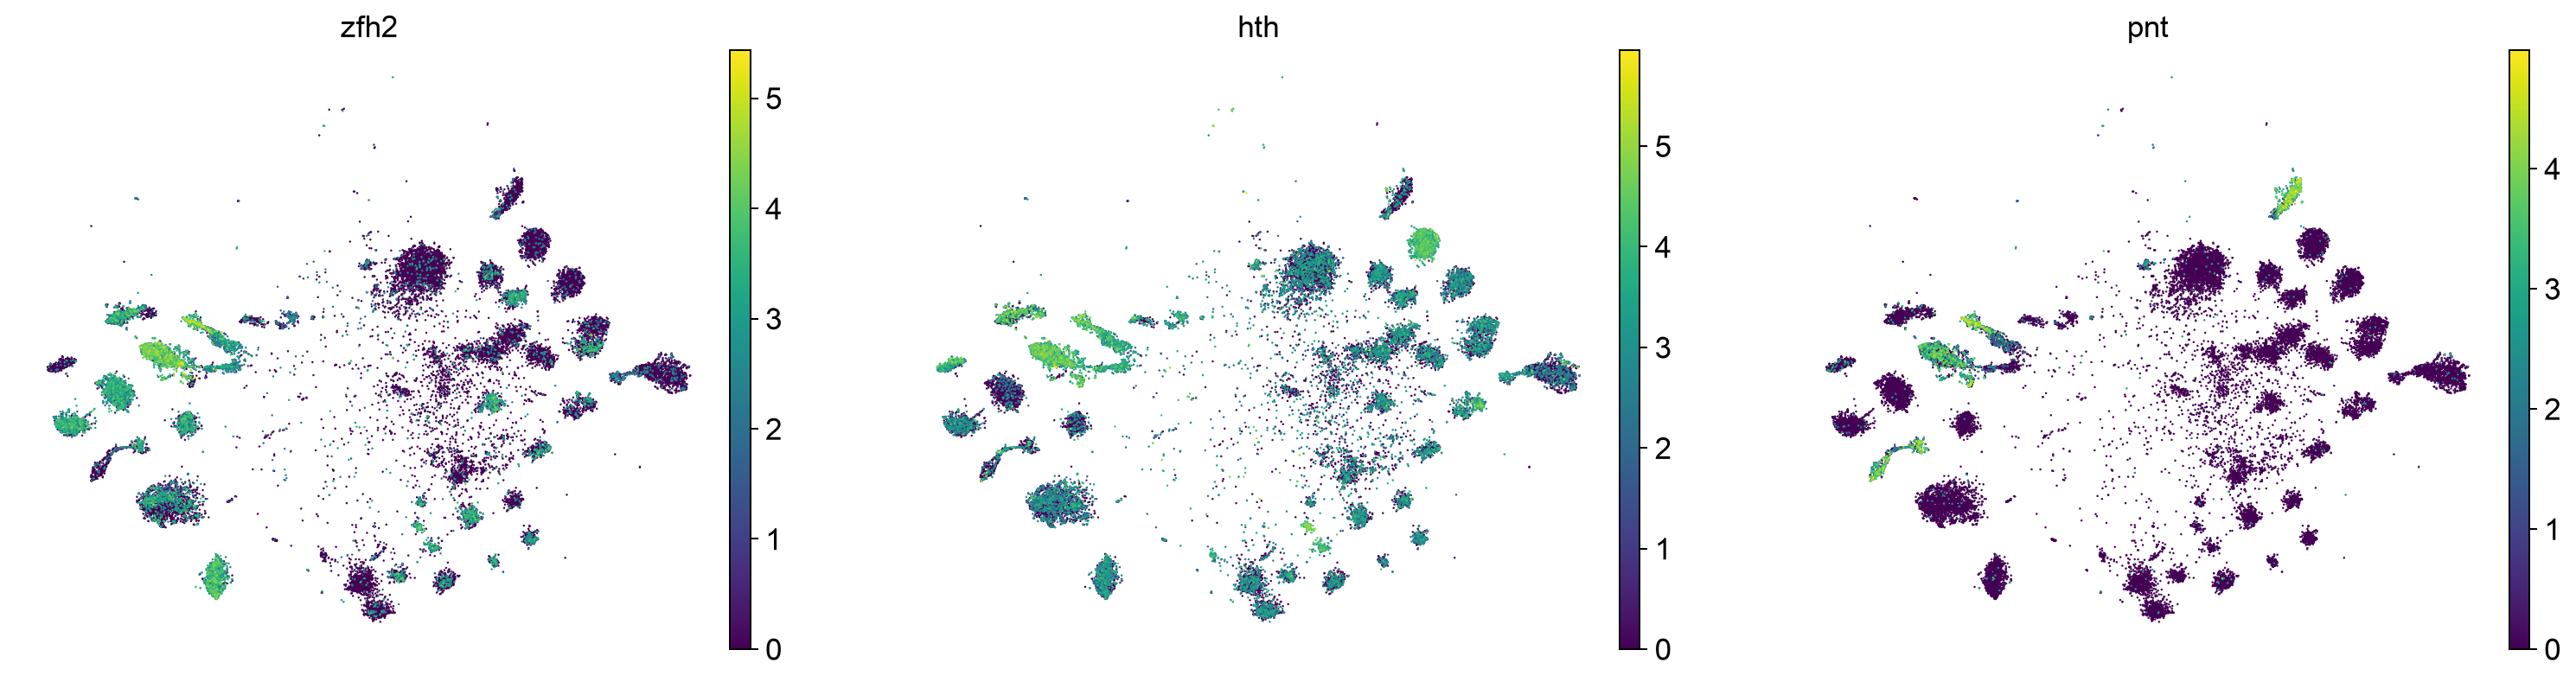

In [19]:
MY_GENES = list(my_tfs["names"].head(3))   # or your own, e.g. ["repo", "ey"]
print(MY_GENES)

sc.pl.tsne(adata, color=MY_GENES, frameon=False, ncols=3)

In [20]:
# The numbers behind that picture, as in section 2.
my_values = sc.get.obs_df(adata, keys=MY_GENES + ["annotation"])
my_means = my_values.groupby("annotation", observed=True).mean()

my_means.sort_values(MY_GENES[0], ascending=False).head(6).round(2)

,zfh2,hth,pnt
annotation,,,
adult brain cell body glial cell,2.97,2.04,1.37
ensheathing glial cell,2.66,3.41,1.26
lamina monopolar neuron L3,2.65,1.45,0.03
adult reticular neuropil associated glial cell,2.57,3.15,1.59
lamina wide-field 1 neuron,2.39,3.85,0.03
lamina monopolar neuron L1,2.25,1.05,0.04


## 4. An earlier stage: the larval brain

> **Optional.**

The Fly Cell Atlas samples adult flies, which have no dividing neural
progenitors. The larval brain does. Ravenscroft et al. 2019 profiled 5,056
larval brain cells, annotated with types that have no adult counterpart:

- **NB**, neuroblasts, the neural stem cells
- **GMC**, ganglion mother cells, their dividing progeny
- prefixes `OL` and `CB` distinguish optic lobe from central brain

In [21]:
from scripts.prepare_data import load_larval

larval = load_larval()

print(larval.shape)
larval.obs["annotation"].value_counts().head(8)

  already prepared: larval_brain.h5ad


(1202, 9853)


annotation
OL GMC          255
OL Type I NB    147
CB GMC          133
Hey+ Neurons    105
SUR             105
Type II NB      103
Lamina           88
ENS              71
Name: count, dtype: int64

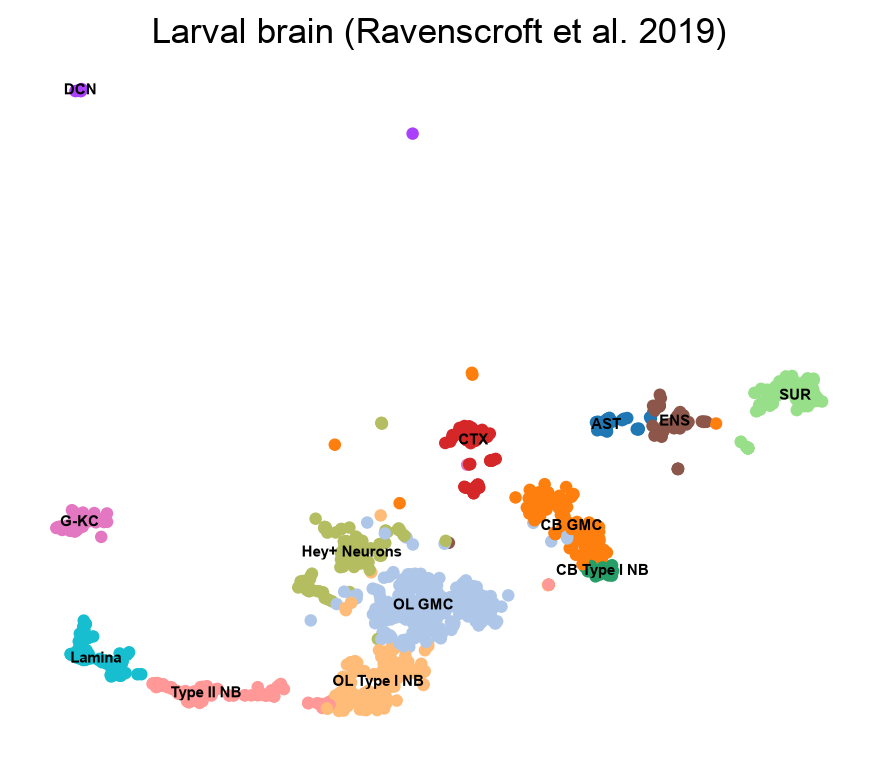

In [22]:
sc.pl.umap(larval, color="annotation", legend_loc="on data", legend_fontsize=6,
           title="Larval brain (Ravenscroft et al. 2019)", frameon=False)

`dpn` (*deadpan*) is a transcription factor expressed in neuroblasts and switched
off as they differentiate. `elav` is conventionally described as a pan-neuronal
marker. Compare them.

In [23]:
larval_values = sc.get.obs_df(larval, keys=["dpn", "elav", "annotation"])
comparison = larval_values.groupby("annotation", observed=True).mean()

comparison.sort_values("dpn", ascending=False).round(2)

,dpn,elav
annotation,,
OL Type I NB,1.40,1.59
CB Type I NB,0.72,1.19
Type II NB,0.47,0.61
OL GMC,0.26,2.60
Lamina,0.20,1.69
Hey+ Neurons,0.07,2.70
CB GMC,0.07,2.36
G-KC,0.05,1.85
CTX,0.04,0.47


This table repays careful reading, because it is not a clean mirror image.

- `dpn` is restricted to the three neuroblast populations
- `elav` is high in neurons and low in glia, so it does separate the two
- `elav` is also high in both ganglion mother cell populations, so it does
  **not** separate progenitors from differentiated neurons

The same lesson as `repo` above: a marker gene is defined by the comparison you
make with it.

Both expression and accessibility data exist for the two stages, which makes
this comparison worth returning to in a project.

## 5. Chromatin accessibility

Expression tells us which genes are transcribed, not which regulatory regions
are responsible. ATAC-seq measures which regions are accessible, and accessible
regions are where transcription factors can bind.

We now use the Janssens ATAC data for the same four cell types, and ask whether
regions near `repo` and `ey` are accessible in the cell types that express them.
Two file types are available per cell type:

- **peaks** (`.bed`), the regions called accessible, about 0.4 MB each
- **coverage tracks** (`.bigwig`), signal at every position, about 58 MB each

The peaks are downloaded. The coverage tracks are not: a bigwig is indexed, so
the next cell returns URLs and every plot below reads only the bytes it needs.
If the network here does not allow that, the cell says so and downloads
instead.

> Offline fallback: run
> `import os; os.environ["ISN_USB"] = "/Volumes/ISN2026"` (Windows: `"E:\\"`)
> before the cell, and files are copied from the USB stick.

In [24]:
from scripts.download_data import janssens_adult_peaks, janssens_adult_bigwigs

peak_files = janssens_adult_peaks(CELL_TYPES)
bigwig_files = janssens_adult_bigwigs(CELL_TYPES)

Janssens et al. 2022 - adult brain peaks per cell type
  already here: KC_g.bed (0.4 MB)
  already here: KC_ab.bed (0.4 MB)
  already here: T1.bed (0.3 MB)
  already here: Astrocyte_like.bed (0.3 MB)
Janssens et al. 2022 - adult brain scATAC bigwigs
  already here: KC_g.bw (57.8 MB)
  already here: KC_ab.bw (61.5 MB)
  already here: T1.bw (28.0 MB)
  already here: Astrocyte_like.bw (41.2 MB)


### Peak files

A peak file is a BED file: one row per accessible region, giving chromosome,
start and end. It is a plain text table, so pandas reads it directly.

In [25]:
kc_peaks = pd.read_csv(
    peak_files["KC_g"], sep="\t", header=None,
    names=["chrom", "start", "end"], usecols=[0, 1, 2],
)
kc_peaks["width"] = kc_peaks["end"] - kc_peaks["start"]

print(f"gamma Kenyon cells: {len(kc_peaks):,} accessible regions")
print(f"median width: {kc_peaks['width'].median():,.0f} bp")
kc_peaks.head()

gamma Kenyon cells: 17,931 accessible regions
median width: 306 bp


,chrom,start,end,width
0,chr2L,5493,6026,533
1,chr2L,34684,35218,534
2,chr2L,66414,67324,910
3,chr2L,72087,72927,840
4,chr2L,73036,73702,666


The median width is a few hundred base pairs, the size range reported for
*Drosophila* enhancers.

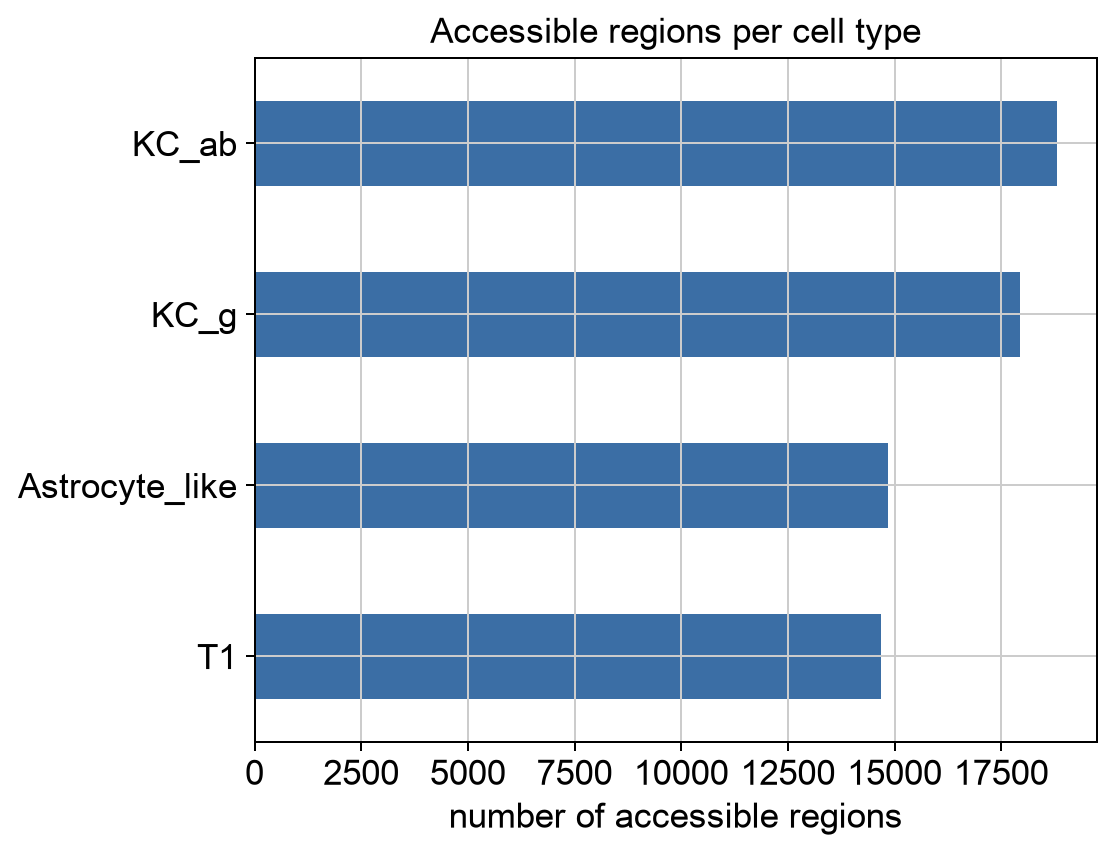

KC_g              17931
KC_ab             18803
T1                14691
Astrocyte_like    14846
dtype: int64

In [26]:
counts = pd.Series({name: sum(1 for _ in open(path)) for name, path in peak_files.items()})

counts.sort_values().plot.barh(color="#3b6ea5")
plt.xlabel("number of accessible regions")
plt.title("Accessible regions per cell type")
plt.show()

counts

The four cell types have comparable numbers of accessible regions, within about
30% of each other. That count also depends on how many cells of each type were
captured and how deeply they were sequenced, so treat it as a rough comparison
rather than a measurement. What distinguishes these cell types is mostly which
regions are open rather than how many, and that is what the rest of this
section looks at.

### Reading a coverage track

A peak call is a binary summary. The bigwig holds the signal itself.
`pyBigWig` is the standard reader. Opening a file and asking for the mean signal
in a window looks like this:

In [27]:
import pyBigWig

with pyBigWig.open(str(bigwig_files["KC_g"])) as bw:
    print("chromosomes:", dict(list(bw.chroms().items())[:4]))
    # mean signal in 5 equal bins across a 2 kb window of the ey locus
    print("signal:", bw.stats("chr4", 712500, 714500, nBins=5, type="mean"))

chromosomes: {'chr2L': 23513712, 'chr2R': 25286936, 'chr3L': 28110227, 'chr3R': 32079331}
signal: [4.282286344528199, 22.895416557312014, 12.510866641998291, 3.494459163665772, 5.619308128356933]


Drawing a whole locus means doing that in many small bins for each cell type and
plotting the result. `scripts/plots.py` wraps exactly that loop, plus the gene
models underneath; open it if you want to see the `pyBigWig` calls it makes.

`repo` was expressed in glia in section 2. The prediction is that regions around
`repo` are accessible in `Astrocyte_like` and not in the three neuronal types.

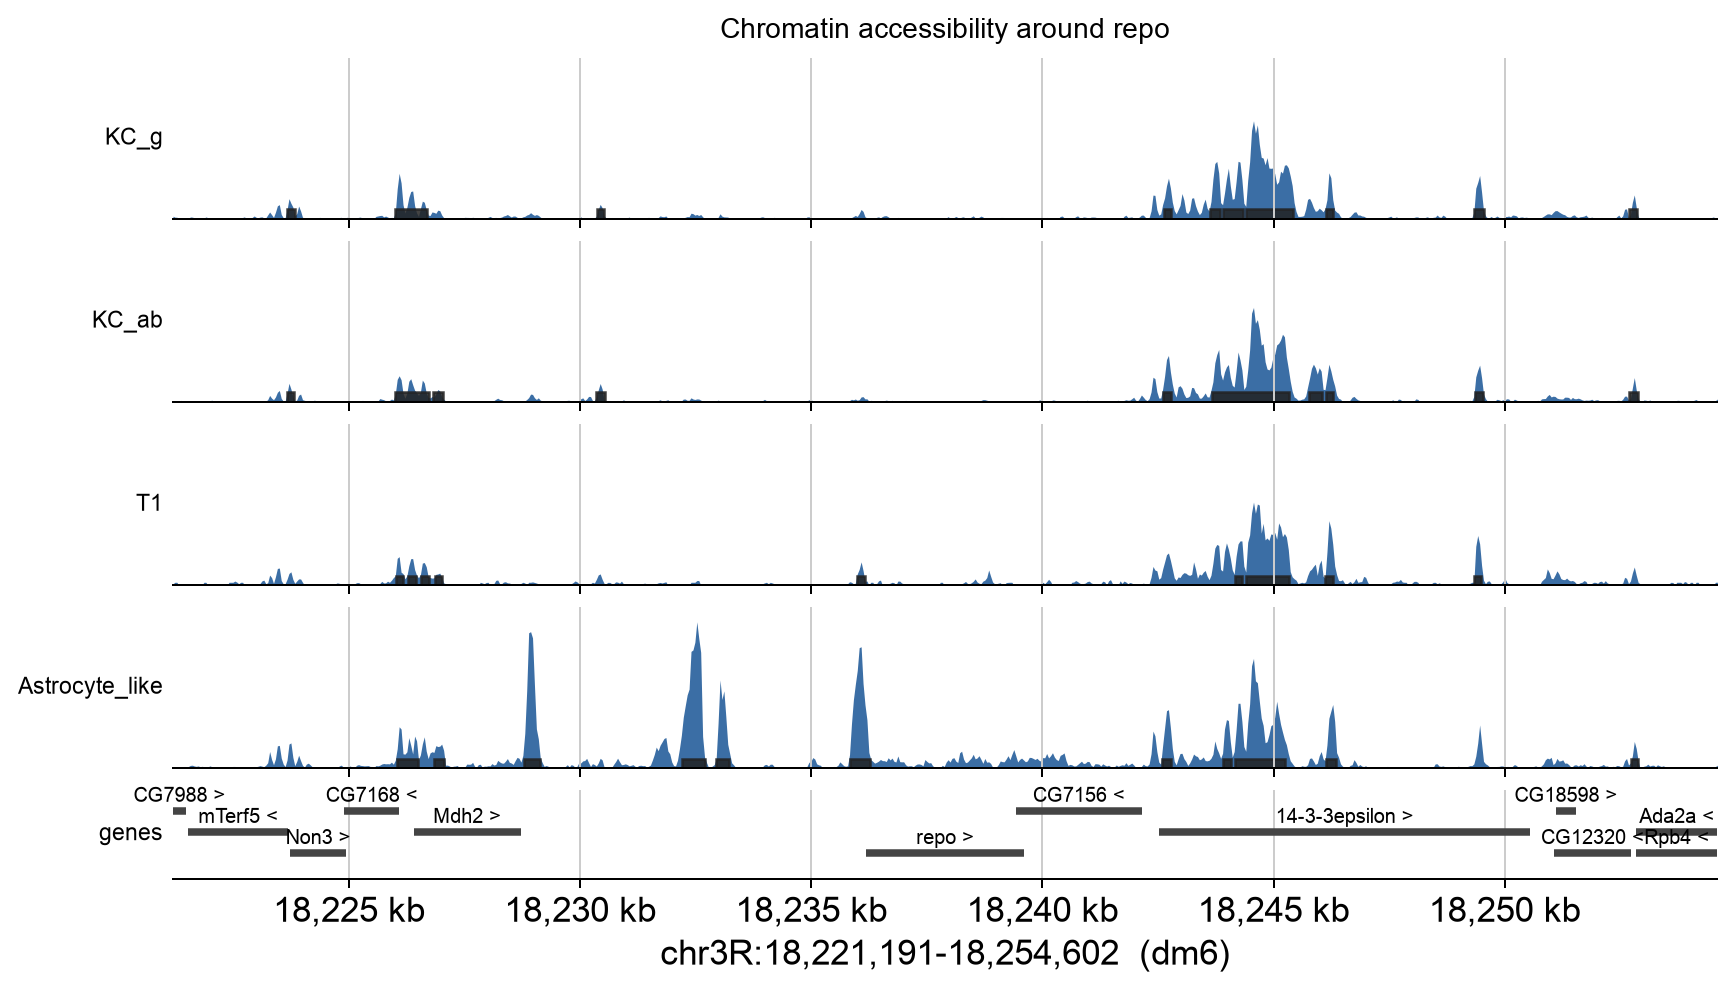

In [28]:
from scripts.plots import plot_tracks

plot_tracks(bigwig_files, gene="repo", flank=15_000, peaks=peak_files)
plt.show()

Reading the figure: one row per cell type on a common y-axis, the filled profile
is ATAC signal, black bars at the base are the called peaks, and the lower panel
shows genes with the arrow indicating strand.

Several regions upstream of `repo` carry signal in `Astrocyte_like` and little or
none in the neuronal types, the accessibility counterpart of the expression
pattern in section 2. One peak near the right is present in all four cell types:
regions accessible everywhere are usually promoters rather than
cell-type-specific enhancers.

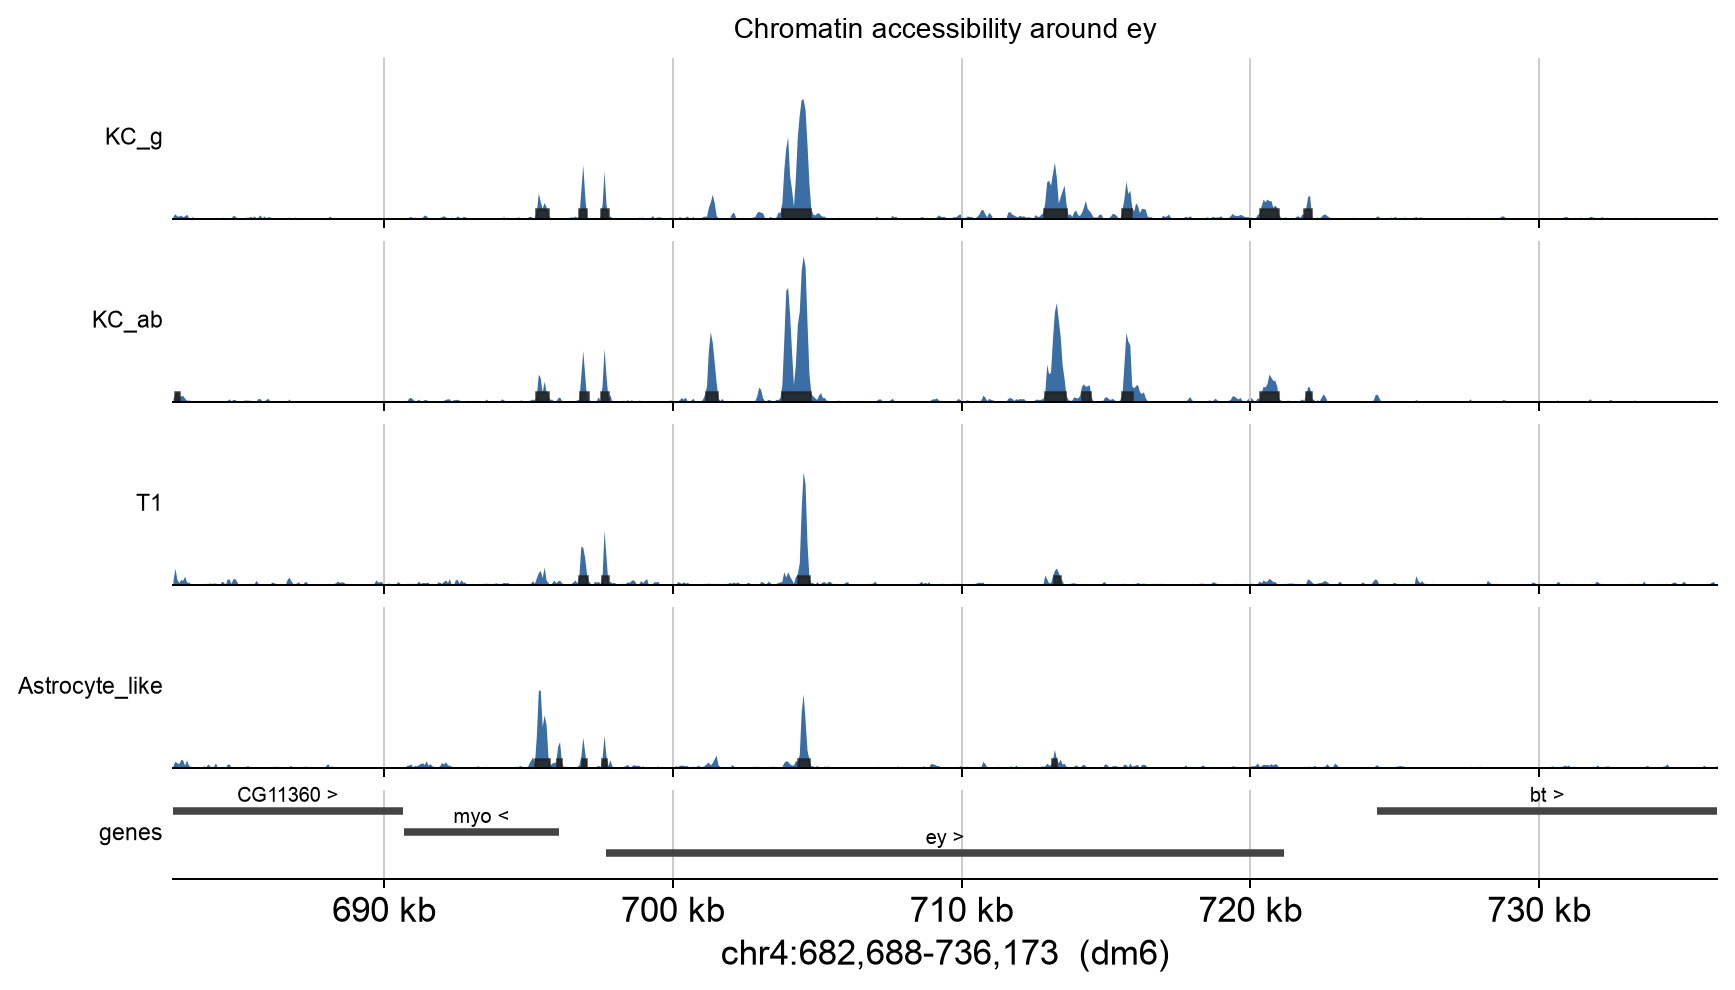

In [29]:
plot_tracks(bigwig_files, gene="ey", flank=15_000, peaks=peak_files)
plt.show()

Within the `ey` locus the peaks near 713 kb are higher in `KC_g` and `KC_ab` than
in `T1` or `Astrocyte_like`. This region is intronic rather than
promoter-proximal, which is typical: enhancers are frequently in introns,
downstream of the gene, or tens of kilobases away.

### Your turn

Pick a gene and compare its expression with its accessibility. Gene symbols are
case-sensitive and not uniformly lower case: FlyBase capitalises symbols first
identified through a dominant allele or named by homology, so it is `alrm` and
`elav` but `Imp` and `Eaat1`.

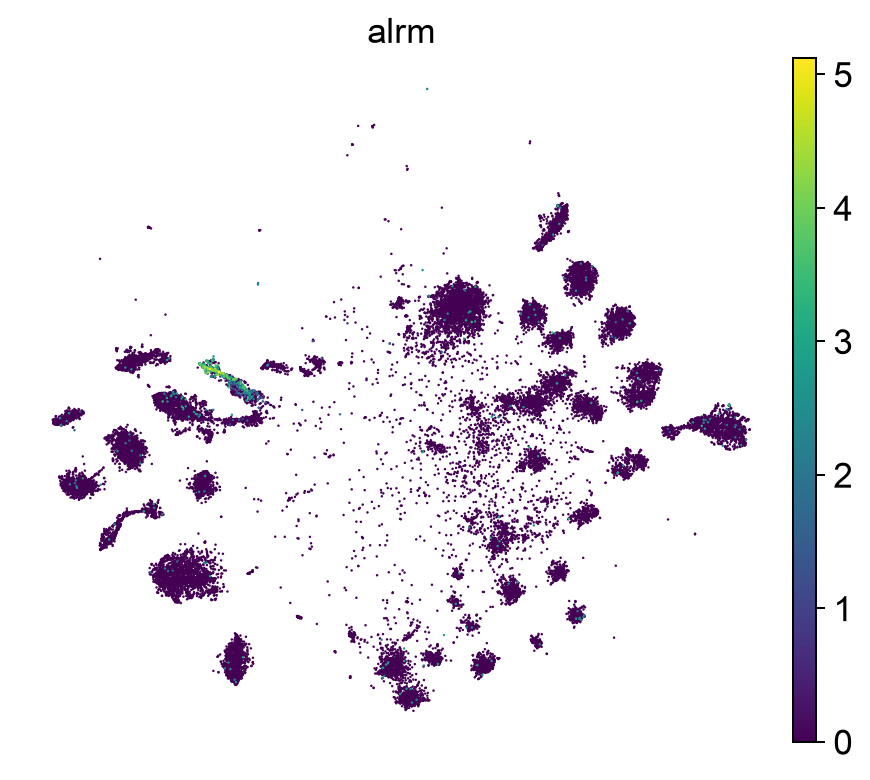

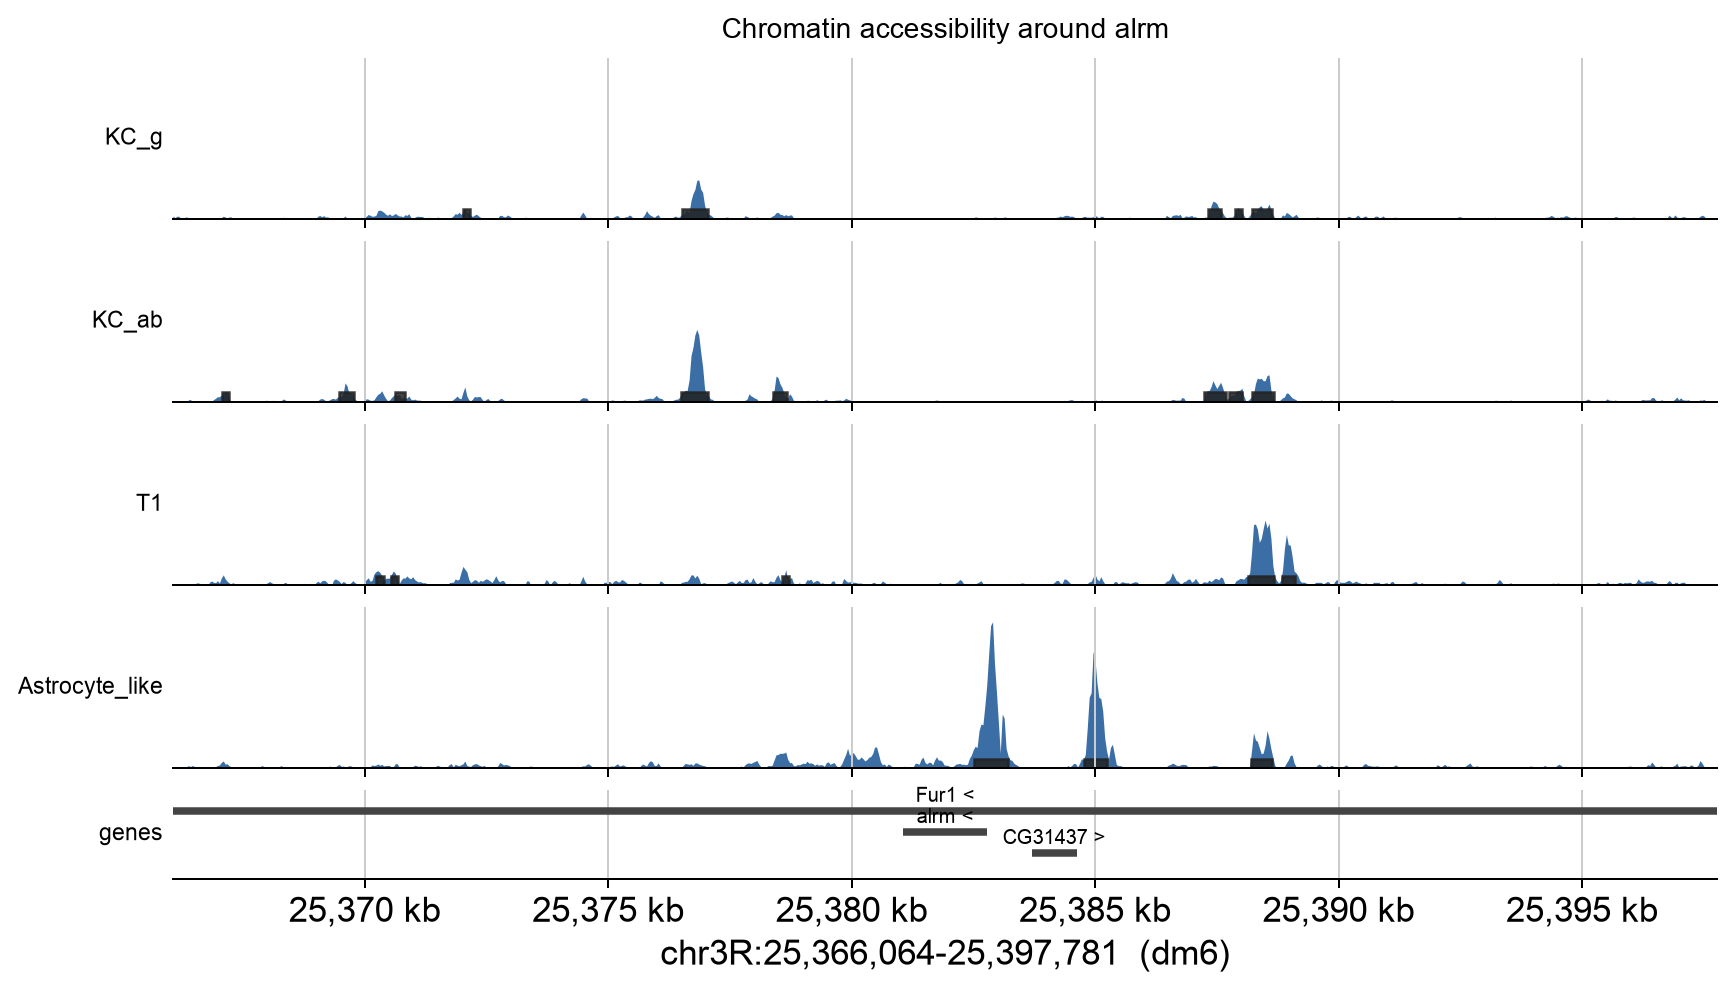

In [30]:
MY_GENE = "alrm"      # change this, then re-run the cell

sc.pl.tsne(adata, color=MY_GENE, frameon=False)
plot_tracks(bigwig_files, gene=MY_GENE, flank=15_000, peaks=peak_files)
plt.show()

For each gene, record whether the cell type with the highest expression is also
the one with the strongest accessibility. Disagreements are informative: a
region can be accessible without the nearby gene being transcribed.

### The same data in a genome browser

Everything plotted above is also a public UCSC track hub, published by the
authors. No download, no code:

[Open the Janssens tracks in the UCSC browser](https://genome.ucsc.edu/cgi-bin/hgTracks?db=dm6&hubUrl=https://ucsctracks.aertslab.org/papers/FlyBrain/hub.txt&position=chr2L:20040501-20041072&hideTracks=1&AdultCellTypes=full&KC_g=full&KC_ab=full&T1=full&Astrocyte_like=full&enhancersTested=pack)

That opens dm6 at an enhancer used in Practical 6, showing the same four cell
types. The hub holds all 82 adult cell types, the early development tracks and
the 54 enhancers tested in flies. Type a gene name in the search box to move
around.

For one locus the browser is faster than anything here. Code is better when you
want the same figure for 82 cell types, or a record of exactly what was plotted.
Browse to find something; use code to measure it.

## 6. Identifying cell-type-specific regions

> **Optional.**

So far we started from a known gene. The alternative is to find regions that
differ between cell types first, then look at which genes are nearby.

The comparison below finds gamma Kenyon cell peaks that do not overlap any peak
in `T1` or `Astrocyte_like`, on chromosome 4 only to keep it quick. The function
is written out so you can see what an overlap is: two regions overlap when each
starts before the other ends. In practice you would use `bedtools` or
`pyranges`, which do it in one call, genome-wide.

In [31]:
def load_peaks(path):
    return pd.read_csv(path, sep="\t", header=None,
                       names=["chrom", "start", "end"], usecols=[0, 1, 2])

def overlaps_any(row, other):
    same = other[other["chrom"] == row["chrom"]]
    return ((same["start"] < row["end"]) & (same["end"] > row["start"])).any()

kc = load_peaks(peak_files["KC_g"])
others = pd.concat([load_peaks(peak_files[c]) for c in ["T1", "Astrocyte_like"]])

kc_chr4 = kc[kc["chrom"] == "chr4"].copy()
kc_chr4["specific"] = ~kc_chr4.apply(overlaps_any, other=others, axis=1)

specific = kc_chr4[kc_chr4["specific"]]
print(f"{len(specific)} of {len(kc_chr4)} gamma Kenyon cell peaks on chr4 "
      f"are not accessible in T1 or astrocytes")
specific.head(10)

30 of 141 gamma Kenyon cell peaks on chr4 are not accessible in T1 or astrocytes


,chrom,start,end,specific
14491,chr4,104075,104418,True
14492,chr4,111809,111955,True
14502,chr4,207112,207314,True
14506,chr4,275888,276040,True
14511,chr4,313386,313564,True
14519,chr4,395619,395906,True
14525,chr4,418832,419012,True
14528,chr4,426154,426350,True
14529,chr4,426775,427491,True
14530,chr4,437584,437990,True


In [32]:
from scripts.genes import genes_in_window

for _, r in specific.head(5).iterrows():
    near = genes_in_window(r["chrom"], r["start"] - 10_000, r["end"] + 10_000)
    names = ", ".join(near.index[:4]) if len(near) else "no gene within 10 kb"
    print(f"{r['chrom']}:{r['start']:,}-{r['end']:,}   nearby: {names}")

chr4:104,075-104,418   nearby: pan
chr4:111,809-111,955   nearby: pan, Ank
chr4:207,112-207,314   nearby: CG31998, Crk, CG31999
chr4:275,888-276,040   nearby: NfI, lncRNA:CR44023, Syt7
chr4:313,386-313,564   nearby: Syt7, Rad23, Zip102B, CG32850


Proximity is not evidence of regulation. It identifies candidates, which would
need experimental testing to confirm.

## 7. Candidate regions for Practical 6

In Practical 6 these sequences are given to DeepFlyBrain, a network trained on
this ATAC data, to ask which transcription factor motifs it uses to classify
them.

Two worked examples are filled in, one per cell type, found the same way as the
comparison above but run genome-wide rather than on chromosome 4, which is why
neither appears in the list printed there. Both are exactly 500 bp, the input
size DeepFlyBrain expects; when you add your own, centre it on the peak.

The first sits at `Rgk1`, which section 3 found to be one of the strongest gamma
Kenyon cell markers. A cell-type-specific accessible region beside a
cell-type-specific gene is the pattern we have been looking for.

In [33]:
MY_REGIONS = [
    ("chr2R", 19346269, 19346769, "near Rgk1, Kenyon cell specific"),
    ("chr3R", 18232201, 18232701, "near repo, astrocyte specific"),
]

out = ROOT / "data" / "processed" / "practical5_candidate_regions.bed"
out.parent.mkdir(parents=True, exist_ok=True)
with open(out, "w") as fh:
    for chrom, start, end, note in MY_REGIONS:
        fh.write(f"{chrom}\t{start}\t{end}\t{note}\n")

print(f"Wrote {len(MY_REGIONS)} regions to {out.relative_to(ROOT)}")

Wrote 2 regions to data/processed/practical5_candidate_regions.bed


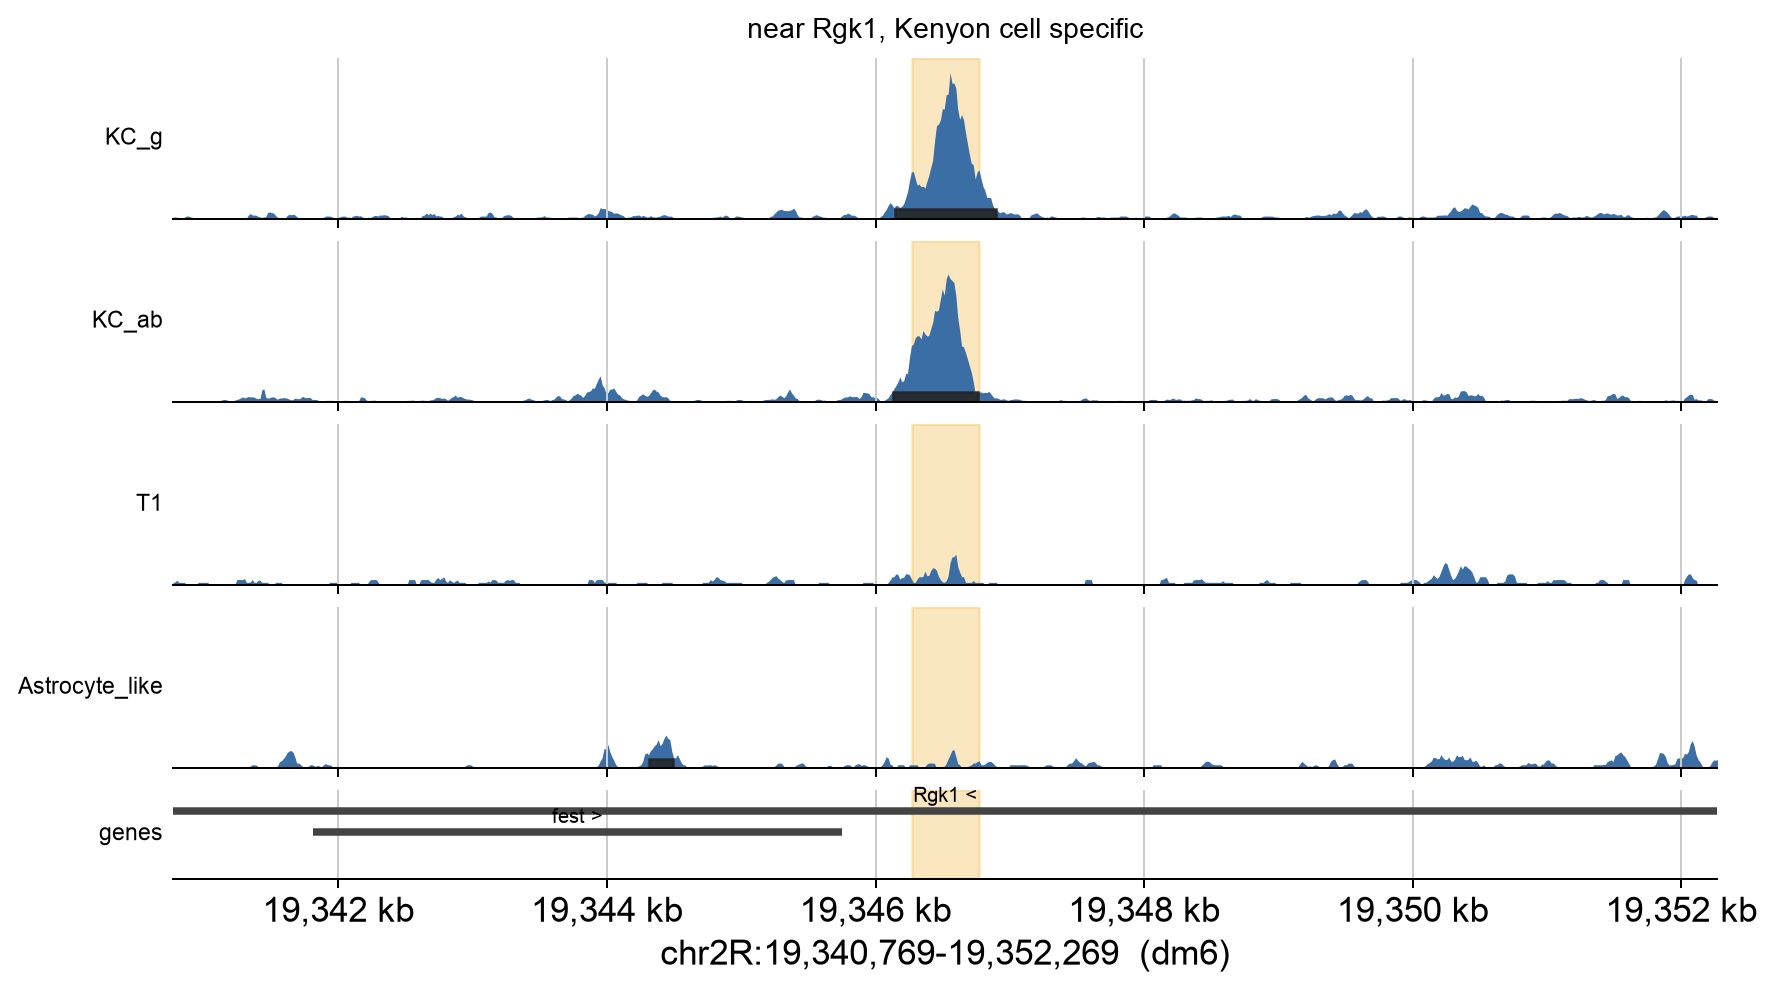

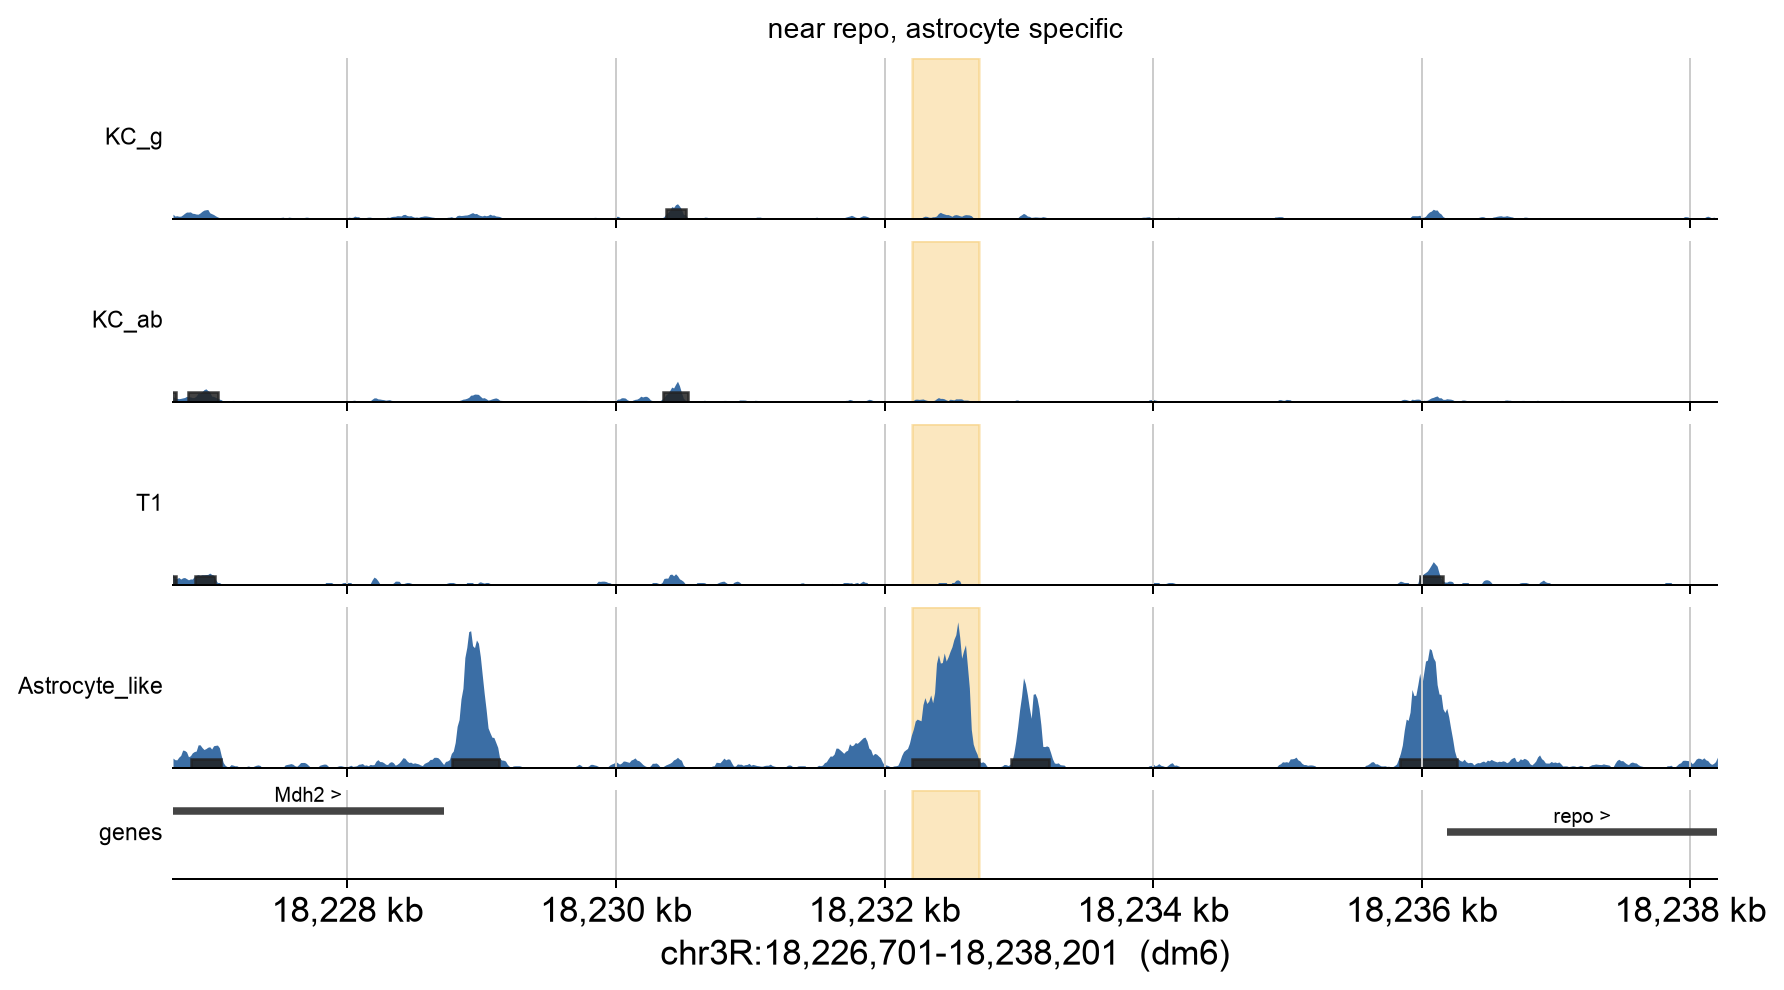

In [34]:
for chrom, start, end, note in MY_REGIONS:
    plot_tracks(bigwig_files, region=(chrom, start - 5_500, end + 5_500),
                peaks=peak_files, highlight=(start, end), title=note)
    plt.show()

## Summary

> Can a Kenyon cell be distinguished from a glial cell using published
> single-cell data, and do expression and accessibility give the same answer?

Yes to both. The two cell types separate cleanly in expression, carry different
marker genes and transcription factors, and the regions near those genes are
accessible in the cell type that expresses them. The two measurements agreed
everywhere we looked.

The qualification is that neither is self-interpreting. `repo` is a glial gene
but not a marker of any one glial type, `elav` is called pan-neuronal yet is
present in progenitors, and an accessible region near a gene is not evidence
that it regulates that gene.

Accessibility also leaves the obvious question unanswered: it says a region is
open, not why, and not which transcription factor opens it. That is a question
about the sequence, and it is where Practical 6 begins.

`sc.read_h5ad`, `sc.pl.tsne`, `sc.pl.dotplot` and
`sc.tl.rank_genes_groups` are the core of most published single-cell analyses,
and work the same way on any dataset you download later.

**For the group project**, record: the cell types compared, one locus where the
difference was unambiguous, the corresponding expression data, and what you
infer the region does.